In [1]:
# import os
# import numpy as np
# import pandas as pd
# from collections import Counter
# from scipy.stats import zscore
# from itertools import combinations

# # ================================================================
# # CONFIG
# # ================================================================
# LAYER_MODE = 'collapsed'

# BASE_DATA_DIR = r"C:\Users\sh2075\Downloads\Coherence_Granger_Motif_Results"
# OUTPUT_DIR    = r"C:\Users\sh2075\Downloads\Coherence_Granger_Motif_Results\motif_outputs"

# GENOTYPES  = ['WT', 'HET', 'KO']
# LAYERS     = ['PrL23', 'PrL5']
# MODALITIES = ['GBO', 'HFO', 'spikes']

# GLOBAL_SEED = 42

# ALL_MOTIF_CLASSES = [
#     '0','I','II','III','IV','V','VI','VII','VIII','IX','X','XI','XII','XIII','Unknown'
# ]

# # ================================================================
# # FILENAME PARSER
# # ================================================================
# def parse_filename(fname):
#     base     = fname.replace('.npy', '')
#     genotype = next((g for g in GENOTYPES  if g in base), None)
#     layer    = next((l for l in LAYERS     if l in base), None)
#     modality = next((m for m in MODALITIES if m in base), None)
#     return genotype, layer, modality, base

# # ================================================================
# # BINARIZATION
# # ================================================================
# def binarize_power_data_channelwise(power_data, percentile=95.0):
#     z          = zscore(power_data, axis=1, nan_policy='omit')
#     thresholds = np.nanpercentile(z, percentile, axis=1)
#     binary     = (z > thresholds[:, None]).astype(np.uint8)
#     return binary

# # ================================================================
# # MOTIF ADJACENCY TENSOR
# # ================================================================
# def build_motif_adjacency_tensor(binary, max_lag_time=3, max_lag_space=2):
#     if binary.shape[0] > binary.shape[1]:
#         binary = binary.T

#     n_channels, n_time = binary.shape
#     A = np.zeros((max_lag_time + 1, n_time, n_channels, n_channels), dtype=np.uint8)

#     for dt in range(max_lag_time + 1):
#         for t in range(n_time - dt):
#             active_i = np.where(binary[:, t])[0]
#             active_j = np.where(binary[:, t + dt])[0]
#             for i in active_i:
#                 for j in active_j:
#                     if abs(i - j) <= max_lag_space:
#                         A[dt, t, i, j] = 1
#     return A

# # ================================================================
# # TRIPLET CLASSIFIER
# # ================================================================
# def classify_triplet(lags):
#     (dn1, dt1), (dn2, dt2) = lags

#     same_space = (dn1 == dn2)
#     same_time  = (dt1 == dt2)
#     ns = len({0, dn1, dn2})
#     nt = len({0, dt1, dt2})

#     if dn1 == 0 and dt1 == 0 and dn2 == 0 and dt2 == 0:
#         return '0'

#     if nt == 1:
#         if ns == 1: return '0'
#         if ns == 2:
#             if same_space: return 'III' if dt1 == 0 else 'I'
#             return 'IV'
#         if ns == 3: return 'IV'

#     if nt == 2:
#         if ns == 1: return 'II'
#         if ns == 2:
#             if same_space: return 'IX'
#             if same_time:  return 'VII'
#             return 'VI'
#         if ns == 3:
#             if same_time:  return 'X'
#             return 'VIII'

#     if nt == 3:
#         if ns == 1: return 'II'
#         if ns == 2: return 'XII'
#         if ns == 3:
#             if same_space: return 'XI'
#             return 'XIII'

#     return 'Unknown'

# # ================================================================
# # TRIPLET EXTRACTION
# # ================================================================
# def extract_triplets(A):
#     DT, T, N, _ = A.shape
#     triplets = []

#     for dt1 in range(DT):
#         for dt2 in range(DT):
#             has_out_dt1 = A[dt1].any(axis=2)
#             has_out_dt2 = A[dt2].any(axis=2)
#             active      = np.argwhere(has_out_dt1 & has_out_dt2)

#             for t, i in active:
#                 js = np.where(A[dt1, t, i])[0]
#                 ks = np.where(A[dt2, t, i])[0]

#                 for j in js:
#                     for k in ks:
#                         dn1 = j - i
#                         dn2 = k - i
#                         if dn1 == 0 and dt1 == 0 and dn2 == 0 and dt2 == 0:
#                             continue
#                         triplets.append(((dn1, dt1), (dn2, dt2)))
#     return triplets

# # ================================================================
# # MOTIF COUNTS
# # ================================================================
# def motif_counts(binary):
#     A        = build_motif_adjacency_tensor(binary)
#     triplets = extract_triplets(A)
#     counts   = Counter(classify_triplet(t) for t in triplets)
#     for cls in ALL_MOTIF_CLASSES:
#         counts.setdefault(cls, 0)
#     return counts

# # ================================================================
# # SURROGATES
# # ================================================================
# def generate_surrogates(binary, n=100, rng=None):
#     if rng is None:
#         rng = np.random.default_rng()

#     n_channels, n_time = binary.shape
#     surrogates = []

#     for _ in range(n):
#         surrogate = np.zeros_like(binary)

#         for ch in range(n_channels):
#             spike_times = np.where(binary[ch])[0]
#             if len(spike_times) == 0:
#                 continue
#             isis = np.diff(spike_times)
#             if len(isis) == 0:
#                 continue
#             shuffled_isis = rng.permutation(isis)
#             start     = rng.integers(0, max(1, n_time // 4))
#             new_times = np.concatenate([[start], start + np.cumsum(shuffled_isis)])
#             new_times = new_times[new_times < n_time].astype(int)
#             if len(new_times) > 0:
#                 surrogate[ch, new_times] = 1

#         perm      = rng.permutation(n_channels)
#         surrogate = surrogate[perm, :]
#         surrogates.append(surrogate)

#     return surrogates

# # ================================================================
# # Z-STATS
# # ================================================================
# def compute_z(actual, sur_list):
#     zvals, means, stds = {}, {}, {}

#     for cls in ALL_MOTIF_CLASSES:
#         a  = actual[cls]
#         s  = np.array([c[cls] for c in sur_list])
#         mu = s.mean()
#         sd = s.std(ddof=1) if len(s) > 1 else 0
#         zvals[cls] = (a - mu) / (sd + 1e-9)
#         means[cls] = mu
#         stds[cls]  = sd

#     return zvals, means, stds

# # ================================================================
# # PIPELINE
# # ================================================================
# def run_pipeline(data, label):
#     print("Processing:", label)

#     # ---- Spike handling ----
#     if "spikes" in label.lower():
#         print(" → Detected spike data")
#         if data.shape[0] > data.shape[1]:
#             print(" → Transposing")
#             data = data.T
#         thr    = np.percentile(data, 99)
#         binary = (data > thr).astype(np.uint8)
#         if np.sum(binary) < 50:
#             print("Too sparse at 99%, relaxing to 95%")
#             thr    = np.percentile(data, 95)
#             binary = (data > thr).astype(np.uint8)
#         total_spikes = np.sum(binary)
#         print(f" → Spike count: {total_spikes}, threshold: {thr:.4f}")
#         if total_spikes == 0:
#             print(" No spikes detected → skipping")
#             return

#     # ---- Power data ----
#     else:
#         binary = binarize_power_data_channelwise(data)

#     # ---- Motif + stats ----
#     actual     = motif_counts(binary)
#     rng        = np.random.default_rng(GLOBAL_SEED)
#     surrogates = generate_surrogates(binary, rng=rng)
#     sur_counts = [motif_counts(s) for s in surrogates]
#     z, mu, sd  = compute_z(actual, sur_counts)

#     df = pd.DataFrame({
#         'MotifClass':          ALL_MOTIF_CLASSES,
#         'ZScore':              [z[c]      for c in ALL_MOTIF_CLASSES],
#         'ActualCount':         [actual[c] for c in ALL_MOTIF_CLASSES],
#         'SurrogateMean':       [mu[c]     for c in ALL_MOTIF_CLASSES],
#         'SurrogateStd':        [sd[c]     for c in ALL_MOTIF_CLASSES],
#         'PercentilePerChannel': 98,
#         'MaxLagTime':           3,
#         'MaxLagSpace':          1,
#         'IncludeDT0':           True,
#         'LayerMode':            LAYER_MODE
#     })

#     os.makedirs(OUTPUT_DIR, exist_ok=True)
#     out = os.path.join(OUTPUT_DIR, f"results_{label}.csv")
#     df.to_csv(out, index=False)
#     print(f" → Saved: {out}")

# # ================================================================
# # LOAD DATA
# # ================================================================
# # ================================================================
# # LOAD DATA
# # ================================================================
# print("Loading data...")

# all_data = {g: {} for g in GENOTYPES}

# for genotype in GENOTYPES:
#     genotype_dir = os.path.join(BASE_DATA_DIR, genotype)
#     if not os.path.exists(genotype_dir):
#         print(f" Missing folder: {genotype_dir}")
#         continue

#     for fname in os.listdir(genotype_dir):
#         if not fname.endswith(".npy"):
#             continue

#         _, layer, modality, full_uid = parse_filename(fname)

#         if None in (layer, modality):
#             print(f"Skipping: {fname}")
#             continue

#         # Strip layer AND modality from uid so PrL23/PrL5 files
#         # for the same animal land in the same bucket
#         base_uid = (full_uid
#                     .replace(f'_{layer}', '')
#                     .replace(f'_{modality}', '')
#                     .strip('_'))

#         full_path = os.path.join(genotype_dir, fname)
#         try:
#             data = np.load(full_path)
#         except Exception as e:
#             print(f"Error loading {fname}: {e}")
#             continue

#         condition = f"{layer} {modality}"

#         if base_uid not in all_data[genotype]:
#             all_data[genotype][base_uid] = {}

#         all_data[genotype][base_uid][condition] = data
#         print(f"  Loaded: {fname} → uid='{base_uid}' cond='{condition}'")

# print("Data loaded.")

# # ================================================================
# # RUN ALL — per layer + cross-layer combined
# # ================================================================
# for genotype, recordings in all_data.items():
#     for uid, conds in recordings.items():

#         # --- Per-layer (unchanged) ---
#         for cond, data in conds.items():
#             label = f"{genotype}_{uid}_{cond.replace(' ', '_')}"
#             run_pipeline(data, label)

#         # --- Cross-layer: stack PrL23 + PrL5 per modality ---
#         for modality in MODALITIES:
#             prl23_key = f"PrL23 {modality}"
#             prl5_key  = f"PrL5 {modality}"

#             data_23 = conds.get(prl23_key, None)
#             data_5  = conds.get(prl5_key,  None)

#             if data_23 is None or data_5 is None:
#                 continue

#             # Fix orientation: ensure (channels, time)
#             if data_23.shape[0] > data_23.shape[1]:
#                 data_23 = data_23.T
#             if data_5.shape[0] > data_5.shape[1]:
#                 data_5 = data_5.T

#             # Must have same time length
#             if data_23.shape[1] != data_5.shape[1]:
#                 print(f"Skipping cross-layer {uid} {modality}: time mismatch "
#                       f"({data_23.shape[1]} vs {data_5.shape[1]})")
#                 continue

#             # Stack vertically → (n_ch_23 + n_ch_5, time)
#             combined = np.vstack([data_23, data_5])
#             label    = f"{genotype}_{uid}_PrL23-5_{modality}"
#             run_pipeline(combined, label)

# print("DONE")

Loading data...
  Loaded: 2024-01-10mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_WT__0001_PrL23_GBO.npy → uid='2024-01-10mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_WT__0001' cond='PrL23 GBO'
  Loaded: 2024-01-10mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_WT__0001_PrL23_HFO.npy → uid='2024-01-10mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_WT__0001' cond='PrL23 HFO'
  Loaded: 2024-01-10mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_WT__0001_PrL23_spikes.npy → uid='2024-01-10mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_WT__0001' cond='PrL23 spikes'
  Loaded: 2024-01-10mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_WT__0001_PrL5_GBO.npy → uid='2024-01-10mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_WT__0001' cond='PrL5 GBO'
  Loaded: 2024-01-10mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_WT__0001_PrL5_HFO.npy → uid='2024-01-10mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_WT__0001' cond='PrL5 HFO'
  Loaded: 2024-01-10mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_WT__0001_PrL5_spikes.

In [4]:
# import os
# import re
# import pandas as pd

# # === Paths ===
# INPUT_DIR   = r"C:\Users\sh2075\Downloads\Coherence_Granger_Motif_Results\motif_outputs"
# OUTPUT_FILE = r"C:\Users\sh2075\Downloads\Coherence_Granger_Motif_Results\combined_results.xlsx"

# GENOTYPES  = ['WT', 'HET', 'KO']
# LAYERS     = ['PrL23-5', 'PrL23', 'PrL5']  # PrL23-5 FIRST to avoid partial match with PrL23
# MODALITIES = ['GBO', 'HFO', 'spikes']

# # ================================================================
# # Parser
# # ================================================================
# def parse_filename(filename):
#     name     = os.path.splitext(filename)[0]
#     name     = name.encode('ascii', errors='ignore').decode('ascii')
#     genotype = next((g for g in GENOTYPES  if g in name), None)
#     modality = next((m for m in MODALITIES if m in name), None)
#     layer    = next((l for l in LAYERS     if l in name), None)  # PrL23-5 matched before PrL23
#     return genotype, name, layer, modality

# # ================================================================
# # Load all CSV files
# # ================================================================
# all_dfs = []
# for file in os.listdir(INPUT_DIR):
#     if not (file.endswith(".csv") or file.endswith(".xlsx")):
#         continue

#     filepath = os.path.join(INPUT_DIR, file)
#     try:
#         df = pd.read_csv(filepath)
#     except:
#         df = pd.read_excel(filepath)

#     genotype, uid, layer, modality = parse_filename(file)

#     if None in (genotype, layer, modality):
#         print(f"Skipping: {file}")
#         continue

#     df["Genotype"]     = genotype
#     df["Recording_ID"] = uid
#     df["Layer"]        = layer
#     df["Modality"]     = modality
#     all_dfs.append(df)

# if not all_dfs:
#     raise ValueError("No valid files found.")

# combined_df = pd.concat(all_dfs, ignore_index=True)

# # ================================================================
# # Assign clean Mouse_ID — strip layer and modality to get base ID
# # ================================================================
# def get_base_id(recording_id):
#     name = recording_id
#     name = re.sub(r'_PrL23-5|_PrL23|_PrL5', '', name)  # PrL23-5 first
#     name = re.sub(r'_(GBO|HFO|spikes).*$', '', name)
#     name = re.sub(r'^results_', '', name)
#     return name.strip('_')

# combined_df["Base_ID"] = combined_df["Recording_ID"].apply(get_base_id)

# # Mouse_1, Mouse_2 ... per genotype
# genotype_base_ids = (combined_df
#                      .groupby("Genotype")["Base_ID"]
#                      .unique()
#                      .to_dict())

# mouse_id_map = {}
# for genotype, base_ids in genotype_base_ids.items():
#     for i, base_id in enumerate(sorted(base_ids), start=1):
#         mouse_id_map[(genotype, base_id)] = f"Mouse_{i}"

# combined_df["Mouse_ID"] = combined_df.apply(
#     lambda r: mouse_id_map[(r["Genotype"], r["Base_ID"])], axis=1
# )

# # ================================================================
# # Save
# # ================================================================
# combined_df.to_excel(OUTPUT_FILE, index=False)

# print(f"Saved: {OUTPUT_FILE}")
# print(f"Total rows: {len(combined_df)}")
# print(f"\nRows per Layer:")
# print(combined_df["Layer"].value_counts())
# print(f"\nMouse ID mapping:")
# for (genotype, base_id), mouse_id in sorted(mouse_id_map.items()):
#     print(f"  {genotype} | {mouse_id} | {base_id}")

Saved: C:\Users\sh2075\Downloads\Coherence_Granger_Motif_Results\combined_results.xlsx
Total rows: 6075

Rows per Layer:
Layer
PrL23-5    2025
PrL23      2025
PrL5       2025
Name: count, dtype: int64

Mouse ID mapping:
  HET | Mouse_1 | HET_4-01-26mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_HET__0005
  HET | Mouse_2 | HET_4-01-29mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_HET__0005
  HET | Mouse_3 | HET_4-01-29mPFC_Slice4_LC_to_mPFC_hsyn_ChR2_eYFP_vehicle_HET__0005
  HET | Mouse_4 | HET_4-06-04__Slice1_HET_S5E2_Chr2_eYFP_mPFC_Baseline__0003
  HET | Mouse_5 | HET_4-06-04__Slice2_HET_S5E2_Chr2_eYFP_mPFC_Baseline__0004
  HET | Mouse_6 | HET_4-06-04__Slice3_HET_S5E2_Chr2_eYFP_mPFC_Baseline__0003
  HET | Mouse_7 | HET_4-06-07__Slice1_S5E2_Chr2_eYFP_mPFC_Baseline__0003
  HET | Mouse_8 | HET_4-06-07__Slice2_HET_mPFC_Baseline__0004
  HET | Mouse_9 | HET_4-06-07__Slice3_HET_S5E2_Chr2_eYFP_mPFC_Baseline__0003
  HET | Mouse_10 | HET_4-06-12__Slice1_S5E2_Chr2_eYFP_mPFC_Baseline__0003
  HET | 

=== SAMPLE ===
          slices  animals
Genotype                 
HET           16        7
KO            14        9
WT            15        7
ZScore: -13.0 to 3000.5

ANIMAL LEVEL
  animal motif-level: 180 tests | p<0.05: 0 | q<0.05: 0 | expected false positives: 9.0
 level Modality   Layer  n_WT  n_HET  n_KO  mean_WT  mean_HET  mean_KO   stat      p  q_fdr
animal      GBO   PrL23     7      7     9   2.3989    2.1050   2.1692 0.2409 0.7882 0.8004
animal      GBO    PrL5     7      7     9   2.6790    2.3591   2.4537 0.3120 0.7355 0.8004
animal      GBO PrL23-5     7      7     9   2.8721    2.5729   2.7117 0.2252 0.8004 0.8004
animal      HFO   PrL23     7      7     9   1.8301    1.5362   1.7259 0.5089 0.6087 0.8004
animal      HFO    PrL5     7      7     9   2.1741    1.8357   1.8662 0.8385 0.4470 0.8004
animal      HFO PrL23-5     7      7     9   2.3425    2.0066   2.1258 0.6749 0.5205 0.8004


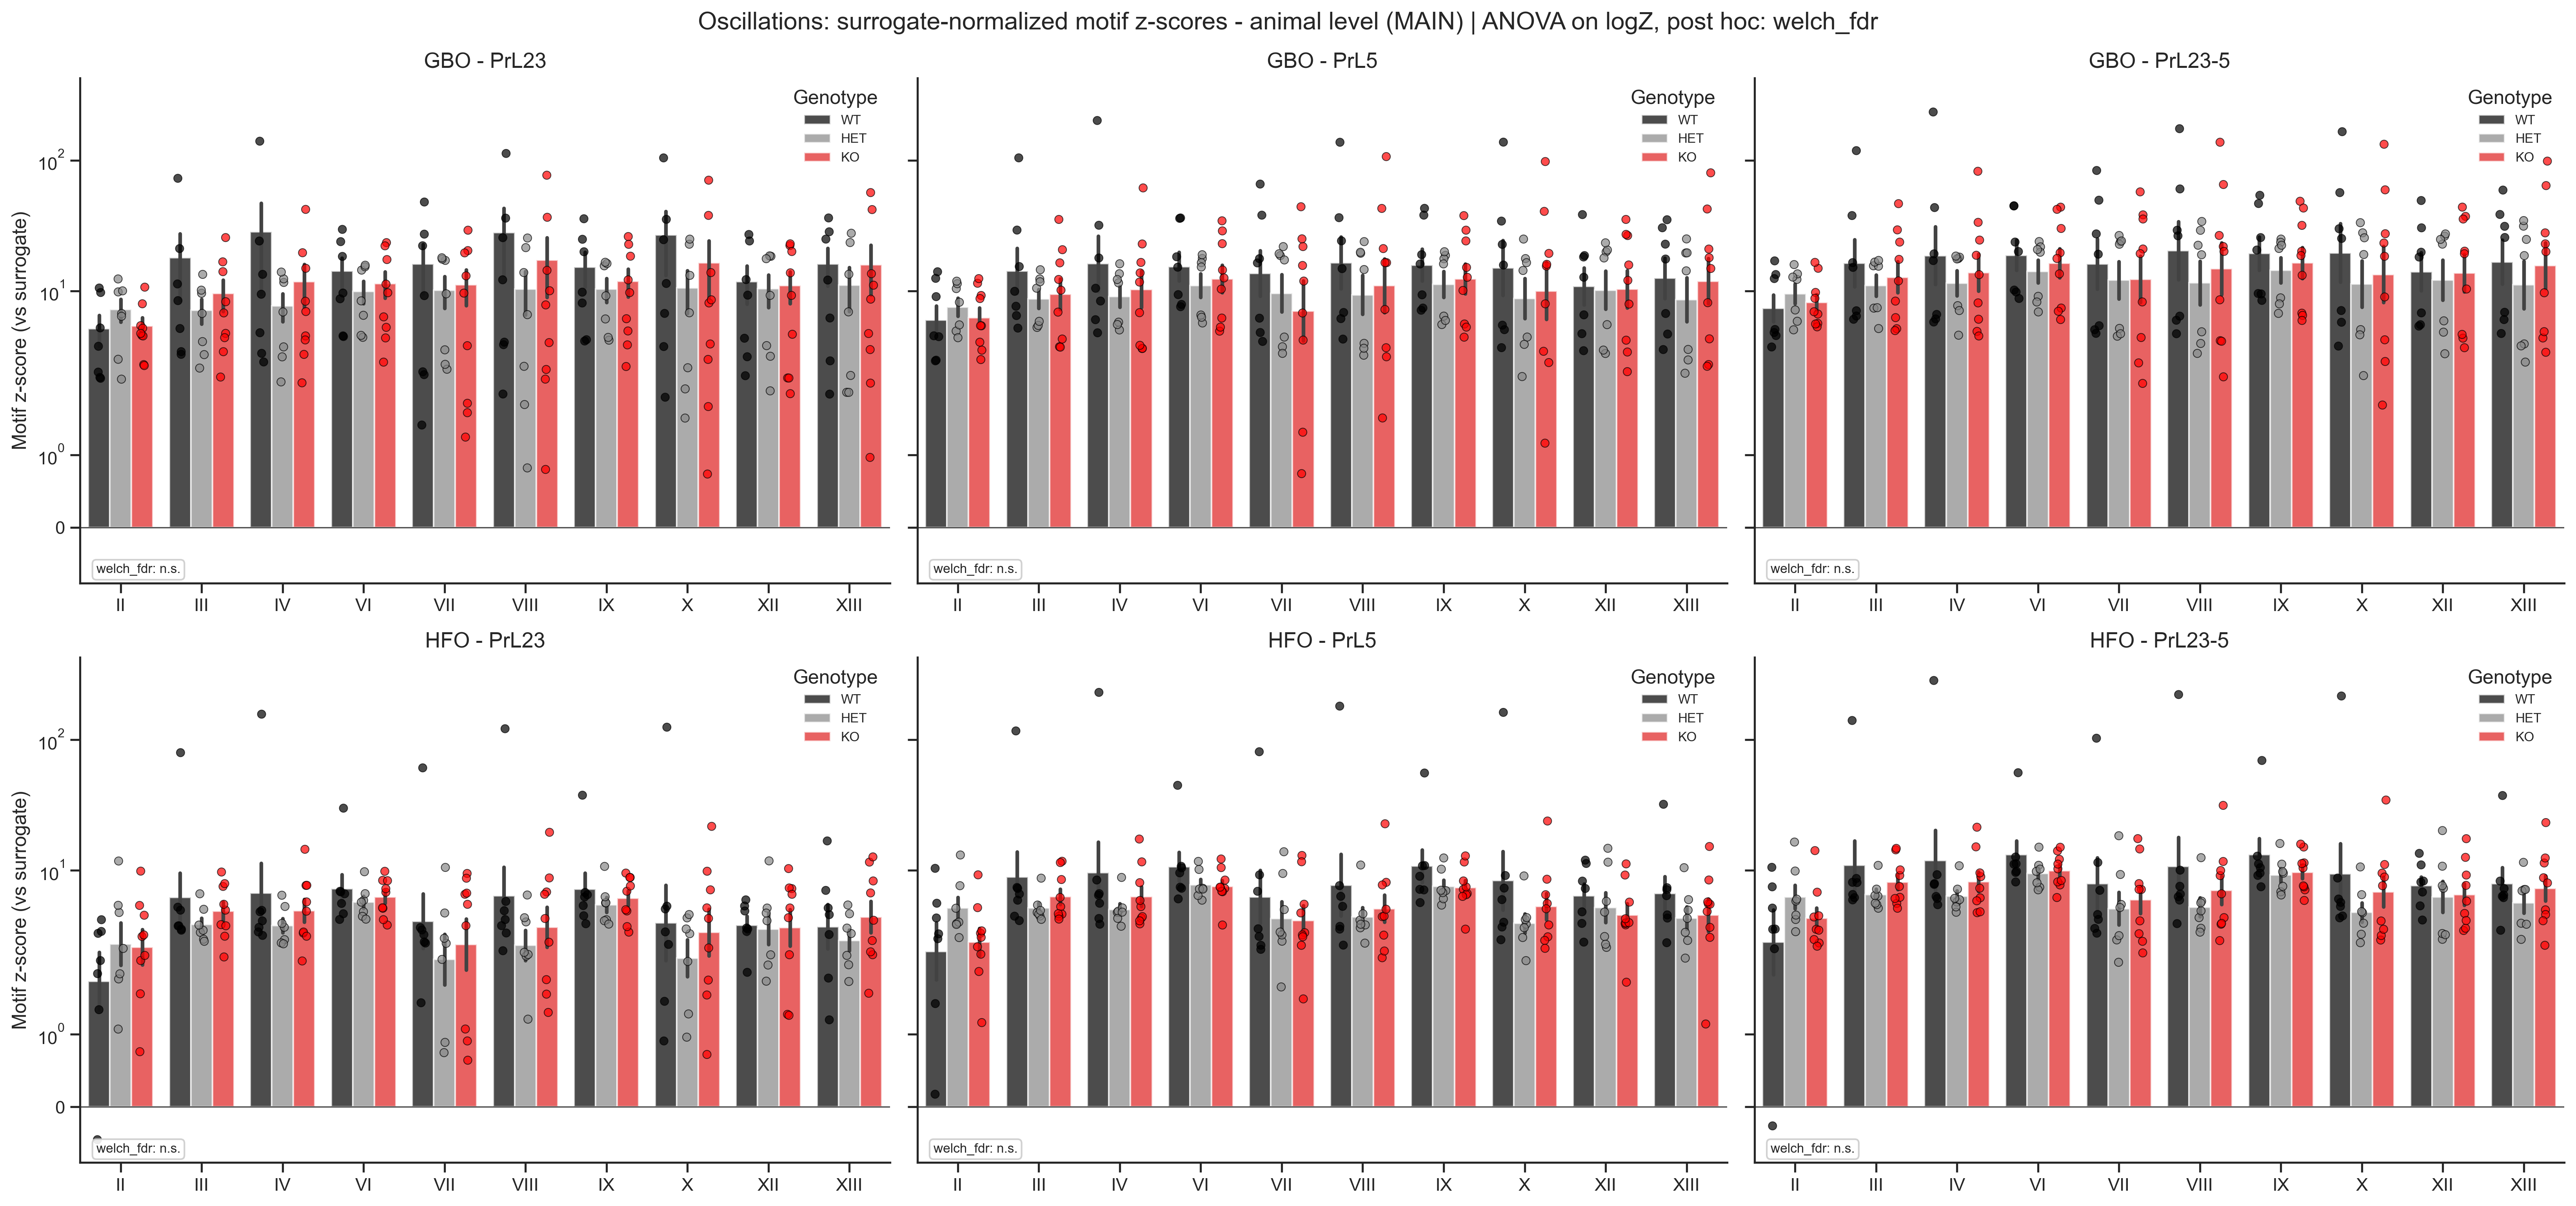

  animal motif-level: 90 tests | p<0.05: 4 | q<0.05: 0 | expected false positives: 4.5
 level Modality   Layer  n_WT  n_HET  n_KO  mean_WT  mean_HET  mean_KO   stat      p  q_fdr
animal   spikes   PrL23     7      7     9   3.5072    2.1979   2.2408 2.1121 0.1472 0.2220
animal   spikes    PrL5     7      7     9   3.3856    2.2182   2.6683 2.1051 0.1480 0.2220
animal   spikes PrL23-5     7      7     9   3.5552    2.5867   2.7974 1.2550 0.3066 0.3066


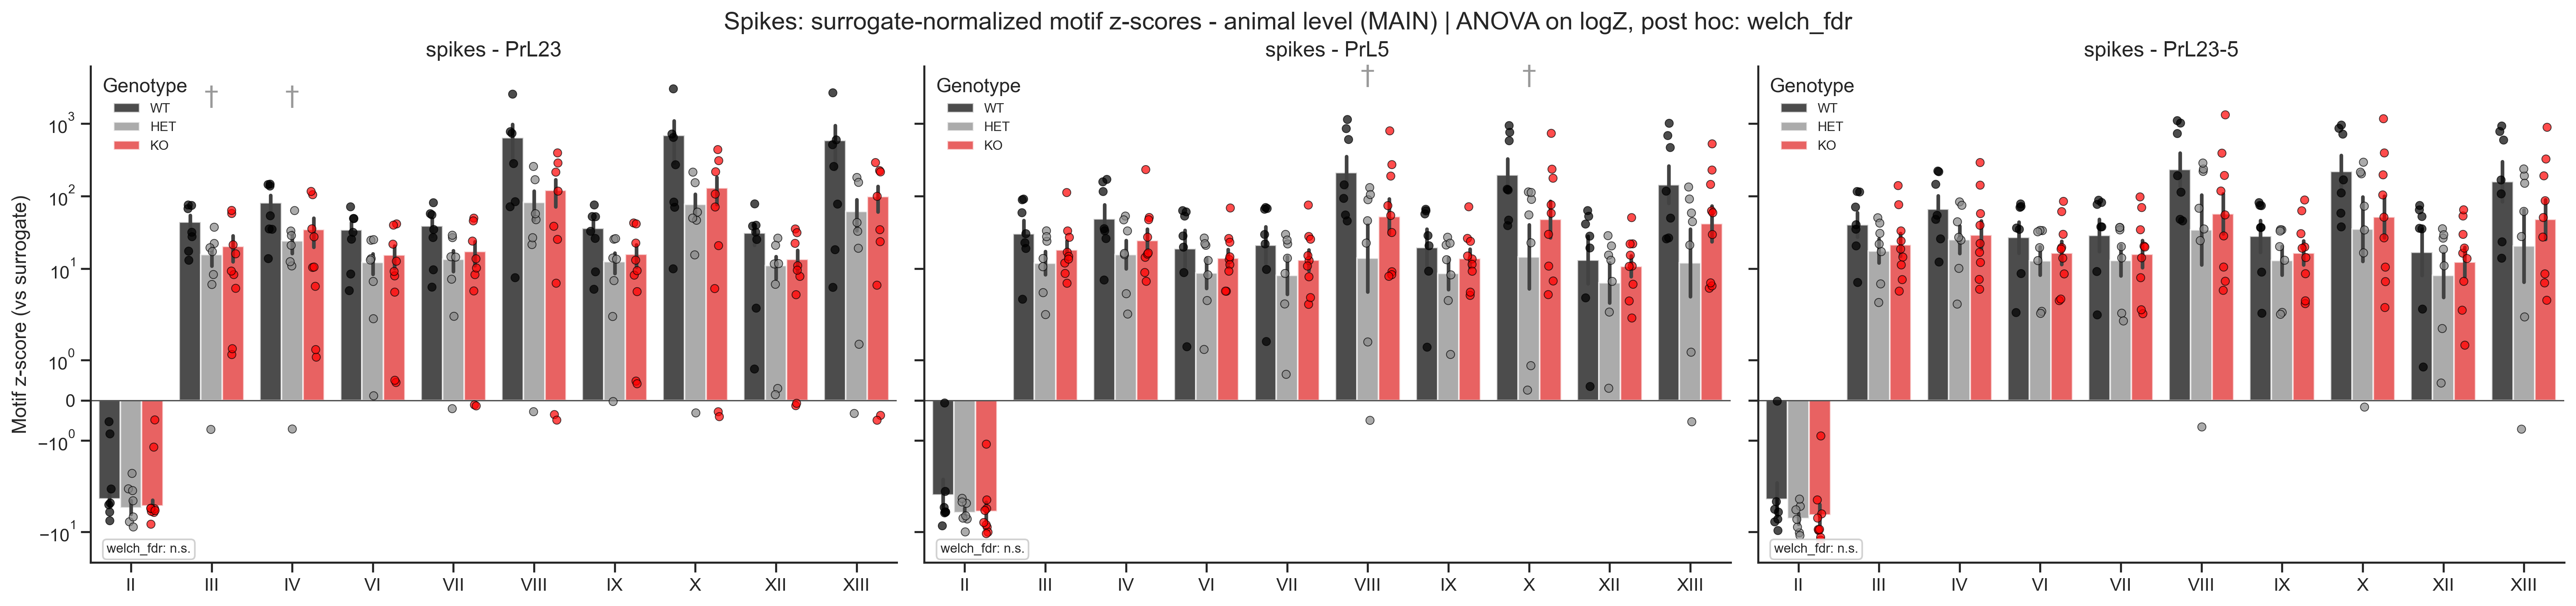


SLICE LEVEL
  slice motif-level: 180 tests | p<0.05: 10 | q<0.05: 0 | expected false positives: 9.0
level Modality   Layer  n_WT  n_HET  n_KO  mean_WT  mean_HET  mean_KO   stat      p  q_fdr
slice      GBO   PrL23    15     16    14   2.4558    2.0995   1.9907 1.0507 0.3587 0.3821
slice      GBO    PrL5    15     16    14   2.7188    2.3132   2.2825 1.2186 0.3059 0.3821
slice      GBO PrL23-5    15     16    14   2.9356    2.5560   2.5342 0.9845 0.3821 0.3821
slice      HFO   PrL23    15     16    14   1.9426    1.4971   1.6308 1.5626 0.2215 0.3821
slice      HFO    PrL5    15     16    14   2.2900    1.7766   1.8176 2.5225 0.0924 0.3821
slice      HFO PrL23-5    15     16    14   2.4645    1.9849   2.0533 2.1065 0.1343 0.3821


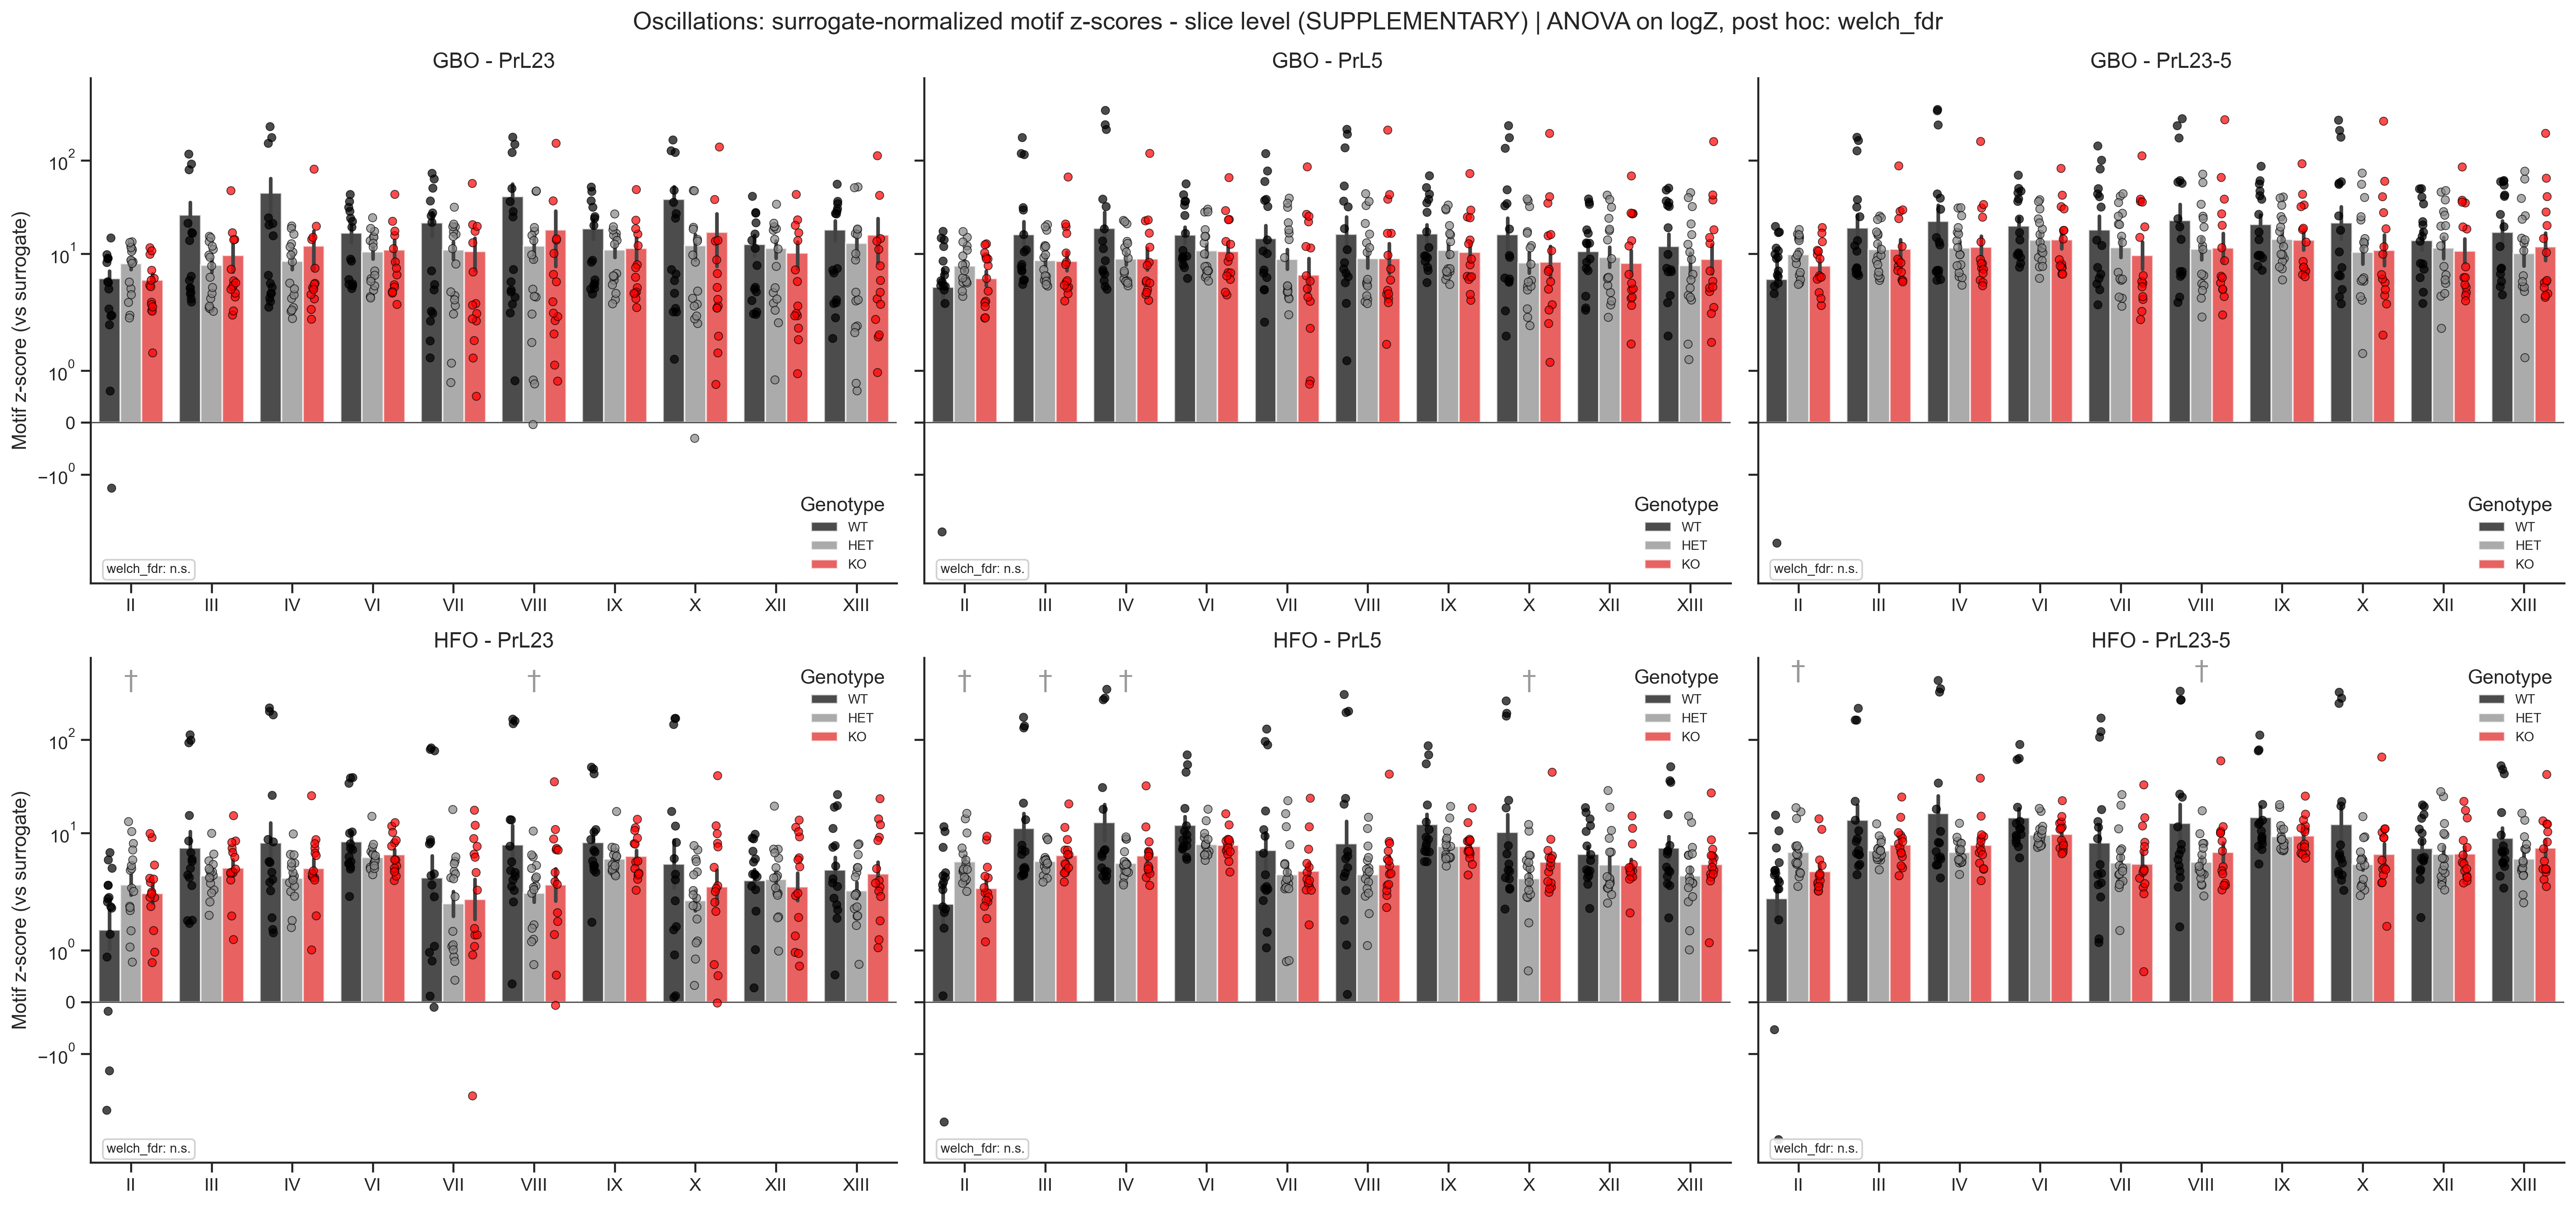

  slice motif-level: 90 tests | p<0.05: 21 | q<0.05: 0 | expected false positives: 4.5
level Modality   Layer  n_WT  n_HET  n_KO  mean_WT  mean_HET  mean_KO   stat      p  q_fdr
slice   spikes   PrL23    15     16    14   3.2453    2.1126   1.9073 3.0652 0.0572 0.0807
slice   spikes    PrL5    15     16    14   3.2452    1.9211   2.4628 3.7699 0.0312 0.0807
slice   spikes PrL23-5    15     16    14   3.4908    2.3960   2.6016 2.6737 0.0807 0.0807


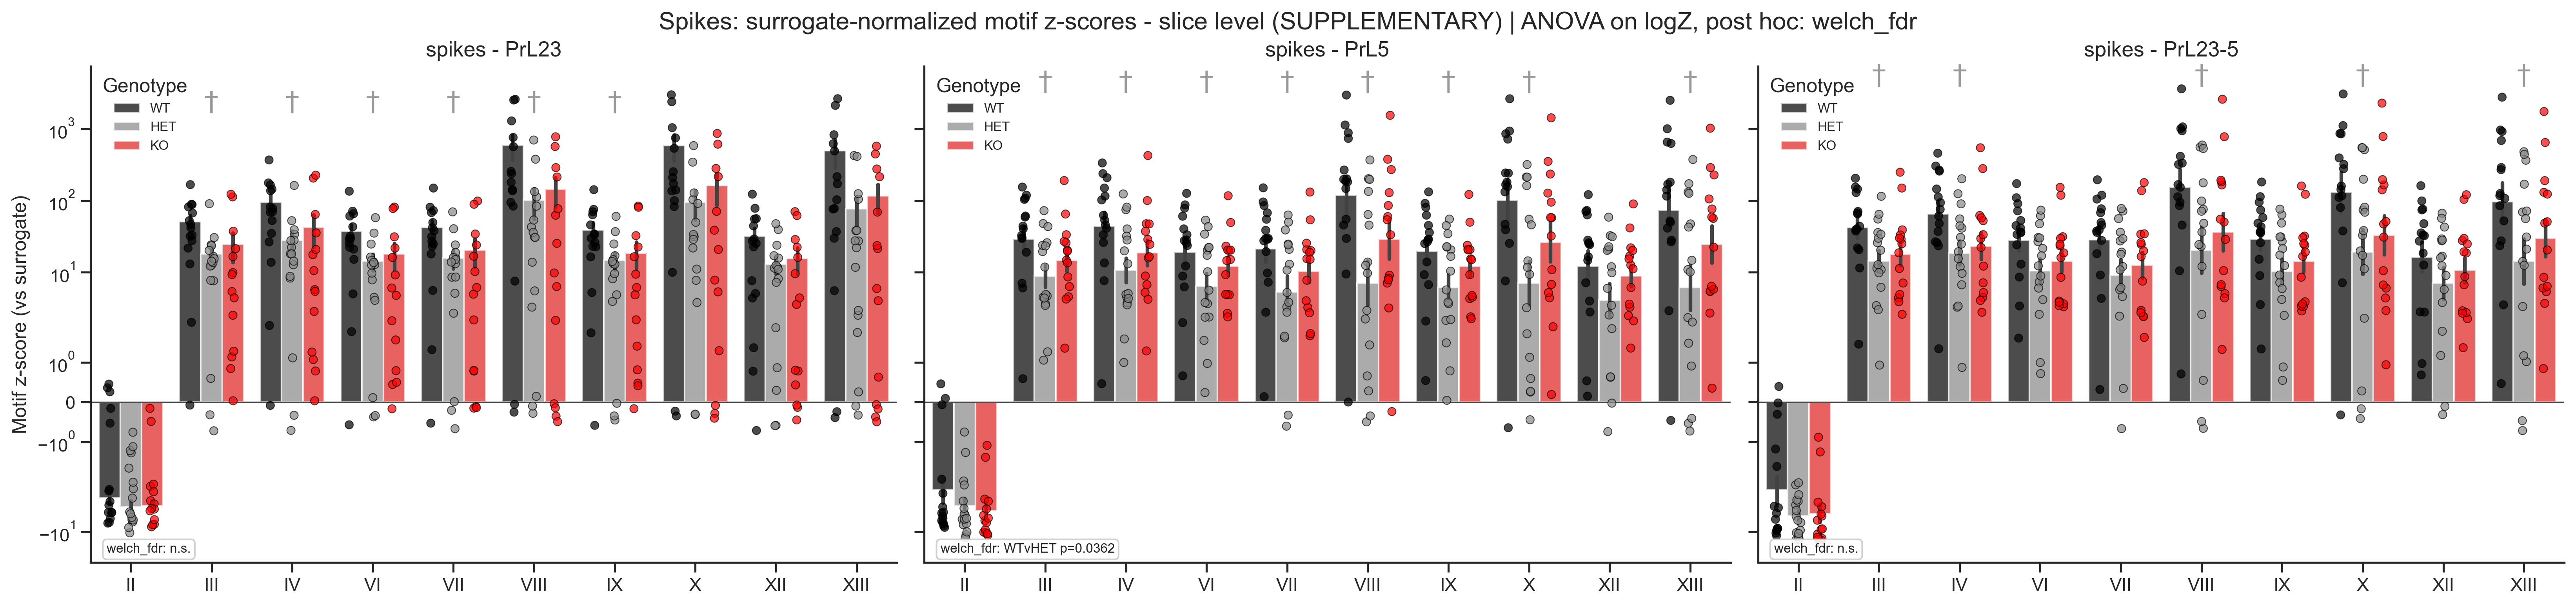

No 'Actual' column -> raw-count supplementary figure skipped.


In [52]:
import warnings; warnings.filterwarnings('ignore')
import os, re, itertools
import pandas as pd, numpy as np, seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import ttest_ind, dunnett, kruskal
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests

# =========================
# CONFIG
# =========================
FILE_PATH = r'D:\UMICH\PaperSubmission\Deep_Learning\Data\Coherence_Granger_Motif_Results\combined_results.xlsx'
SAVE_PATH = r'D:\UMICH\PaperSubmission\Deep_Learning\Data\Coherence_Granger_Motif_Results\output'

FEATURE = 'ZScore'          # (Actual - SurrMean) / SurrStd  -> surrogate-normalized motif z-score
ANALYSIS_VAR = 'logZ'       # 'ZScore' (raw z) | 'logZ' (signed log, recommended for heavy tails)
PLOT_VAR = 'ZScore'         # figures in interpretable z units
PLOT_YSCALE = 'symlog'      # None for linear
RAW_COUNT_COL = 'Actual'    # raw motif counts -> supplementary figure only (skipped if missing)

# POST HOC: 'tukey' | 'games_howell' | 'dunnett' | 'welch_fdr' | 'welch_bonf' | 'welch_holm' | 'kruskal_dunn'
POSTHOC = 'welch_fdr'

GENOTYPES = ['WT', 'HET', 'KO']; CONTROL = 'WT'
LAYERS = ['PrL23', 'PrL5', 'PrL23-5']
OSC_MODALITIES = ['GBO', 'HFO']; SPIKE_MODALITY = 'spikes'
GENOTYPE_COLORS = {'WT': '#000000', 'HET': '#888888', 'KO': '#FF0000'}
DESIRED_MOTIFS = ['I','II','III','IV','V','VI','VII','VIII','IX','X','XI','XII','XIII']
FDR_METHOD = 'fdr_bh'; ALPHA = 0.05

# =========================
# LOAD
# =========================
df = pd.read_excel(FILE_PATH)
df = df[df.Genotype.isin(GENOTYPES) & df.Layer.isin(LAYERS) & df[FEATURE].notnull()].copy()
df = df[df.SurrogateStd > 0].copy()   # structural zeros only; no outlier filter on z-scores

# Animal = genotype + recording date (all slices recorded on one date = one mouse)
def animal_id(b):
    m = re.search(r'^([A-Z]+)_((?:20)?\d{1,4}-\d{2}-\d{2})', str(b))
    return f"{m.group(1)}_{m.group(2).replace('2024-','4-')}" if m else str(b)

df['Animal'] = df.Base_ID.map(animal_id)
df['Slice'] = df.Base_ID
print("=== SAMPLE ===")
print(df.groupby('Genotype').agg(slices=('Slice', 'nunique'), animals=('Animal', 'nunique')))

def build_table(unit, value_col=FEATURE):
    """One value per unit (animal or slice) x modality x layer x motif."""
    keys = list(dict.fromkeys([unit, 'Animal', 'Genotype', 'Modality', 'Layer', 'MotifClass']))
    t = df.groupby(keys, observed=True)[value_col].mean().reset_index()
    t['Unit'] = t[unit]
    if value_col == FEATURE:
        t['logZ'] = np.sign(t[FEATURE]) * np.log1p(np.abs(t[FEATURE]))
    return t

agg = {'animal': build_table('Animal'), 'slice': build_table('Slice')}
print(f"{FEATURE}: {agg['animal'][FEATURE].min():.1f} to {agg['animal'][FEATURE].max():.1f}")

# =========================
# POST HOC (per = one row per unit, columns Genotype + ANALYSIS_VAR)
# =========================
def games_howell(groups, names):
    out = []; k = len(groups)
    for i, j in itertools.combinations(range(k), 2):
        a, b = groups[i], groups[j]; na, nb = len(a), len(b)
        va, vb = a.var(ddof=1)/na, b.var(ddof=1)/nb
        se = np.sqrt(va + vb); q = abs(a.mean() - b.mean()) / (se/np.sqrt(2))
        dfw = (va + vb)**2 / (va**2/(na-1) + vb**2/(nb-1))
        p = stats.studentized_range.sf(q, k, dfw)
        out.append(dict(group1=names[i], group2=names[j], meandiff=b.mean()-a.mean(),
                        **{'p-adj': round(p, 4)}, reject=p < ALPHA))
    return pd.DataFrame(out)

def posthoc(per):
    groups = [per[per.Genotype == g][ANALYSIS_VAR].values for g in GENOTYPES]
    if POSTHOC == 'tukey':
        tk = pairwise_tukeyhsd(per[ANALYSIS_VAR], per.Genotype, alpha=ALPHA)
        return pd.DataFrame(tk.summary().data[1:], columns=tk.summary().data[0])
    if POSTHOC == 'games_howell':
        return games_howell(groups, GENOTYPES)
    if POSTHOC == 'dunnett':
        others = [g for g in GENOTYPES if g != CONTROL]
        r = dunnett(*[per[per.Genotype == g][ANALYSIS_VAR].values for g in others],
                    control=per[per.Genotype == CONTROL][ANALYSIS_VAR].values)
        return pd.DataFrame(dict(group1=CONTROL, group2=others, stat=r.statistic.round(3),
                                 **{'p-adj': r.pvalue.round(4)}, reject=r.pvalue < ALPHA))
    if POSTHOC in ('welch_fdr', 'welch_bonf', 'welch_holm', 'kruskal_dunn'):
        rows = []
        for g1, g2 in itertools.combinations(GENOTYPES, 2):
            a = per[per.Genotype == g1][ANALYSIS_VAR].values
            b = per[per.Genotype == g2][ANALYSIS_VAR].values
            p = (stats.mannwhitneyu(a, b).pvalue if POSTHOC == 'kruskal_dunn'
                 else ttest_ind(a, b, equal_var=False).pvalue)
            rows.append(dict(group1=g1, group2=g2, meandiff=b.mean()-a.mean(), p_raw=p))
        t = pd.DataFrame(rows)
        meth = {'welch_fdr': FDR_METHOD, 'welch_bonf': 'bonferroni',
                'welch_holm': 'holm', 'kruskal_dunn': FDR_METHOD}[POSTHOC]
        t['p-adj'] = multipletests(t.p_raw, method=meth)[1].round(4)
        t['reject'] = t['p-adj'] < ALPHA
        return t
    raise ValueError(f"unknown POSTHOC {POSTHOC!r}")

# =========================
# ONE-WAY ANOVA PER MODALITY x LAYER (each unit contributes ONE value per test)
# value = mean motif z-score across motif classes for that unit
# =========================
def anova_by_layer(data, mods, level):
    an_rows, ph_rows = [], []
    for mod in mods:
        for lay in LAYERS:
            sub = data[(data.Modality == mod) & (data.Layer == lay)]
            per = sub.groupby(['Unit', 'Genotype'], observed=True)[ANALYSIS_VAR].mean().reset_index()
            groups = [per[per.Genotype == g][ANALYSIS_VAR].values for g in GENOTYPES]
            if any(len(x) < 2 for x in groups):
                continue
            F, p = (kruskal(*groups) if POSTHOC == 'kruskal_dunn' else stats.f_oneway(*groups))
            an_rows.append(dict(level=level, Modality=mod, Layer=lay,
                                **{f'n_{g}': len(x) for g, x in zip(GENOTYPES, groups)},
                                **{f'mean_{g}': x.mean() for g, x in zip(GENOTYPES, groups)},
                                stat=F, p=p))
            t = posthoc(per)
            t.insert(0, 'Layer', lay); t.insert(0, 'Modality', mod); t.insert(0, 'level', level)
            ph_rows.append(t)
    an = pd.DataFrame(an_rows)
    an['q_fdr'] = multipletests(an.p, method=FDR_METHOD)[1]     # across modality x layer tests
    return an, pd.concat(ph_rows, ignore_index=True)

# =========================
# MOTIF-LEVEL WELCH + FDR (exploratory)
# =========================
def pairwise_motif(data, mods, level):
    rows = []
    for mod in mods:
        for lay in LAYERS:
            s = data[(data.Modality == mod) & (data.Layer == lay)]
            for mo in [x for x in DESIRED_MOTIFS if x in s.MotifClass.unique()]:
                sm_ = s[s.MotifClass == mo]
                for g1, g2 in itertools.combinations(GENOTYPES, 2):
                    a = sm_[sm_.Genotype == g1][ANALYSIS_VAR].values
                    b = sm_[sm_.Genotype == g2][ANALYSIS_VAR].values
                    if len(a) < 3 or len(b) < 3: continue
                    if np.std(a) == 0 and np.std(b) == 0: continue
                    p = ttest_ind(a, b, equal_var=False).pvalue
                    if np.isnan(p): continue
                    rows.append(dict(level=level, Modality=mod, Layer=lay, MotifClass=mo,
                                     contrast=f'{g1} vs {g2}', n1=len(a), n2=len(b),
                                     mean1=a.mean(), mean2=b.mean(), p_raw=p))
    r = pd.DataFrame(rows)
    r['q_fdr'] = multipletests(r.p_raw, method=FDR_METHOD)[1]
    print(f"  {level} motif-level: {len(r)} tests | p<{ALPHA}: {(r.p_raw < ALPHA).sum()} | "
          f"q<{ALPHA}: {(r.q_fdr < ALPHA).sum()} | expected false positives: {ALPHA*len(r):.1f}")
    return r

# =========================
# FIGURE: one panel per modality x layer
# =========================
def plot_family(data, mods, ph, res, fname, suptitle, var=PLOT_VAR, ylabel='Motif z-score (vs surrogate)',
                yscale=PLOT_YSCALE):
    sns.set_style('ticks')
    fig, axes = plt.subplots(len(mods), 3, figsize=(22, 5*len(mods)), dpi=300, sharey=True, squeeze=False)
    for i, mod in enumerate(mods):
        for j, lay in enumerate(LAYERS):
            ax = axes[i, j]
            sub = data[(data.Modality == mod) & (data.Layer == lay)].copy()
            if sub.empty: ax.axis('off'); continue
            mc = [m for m in DESIRED_MOTIFS if m in sub.MotifClass.unique()]
            sub['MotifClass'] = pd.Categorical(sub.MotifClass, categories=mc, ordered=True)

            sns.barplot(data=sub, x='MotifClass', y=var, hue='Genotype', palette=GENOTYPE_COLORS,
                        ax=ax, order=mc, hue_order=GENOTYPES, dodge=True, alpha=.7, errorbar='se')
            sns.stripplot(data=sub, x='MotifClass', y=var, hue='Genotype', palette=GENOTYPE_COLORS,
                          dodge=True, jitter=True, alpha=.7, size=5, edgecolor='gray', linewidth=.5,
                          ax=ax, order=mc, hue_order=GENOTYPES)
            h, l = ax.get_legend_handles_labels()
            ax.legend(h[:3], l[:3], title='Genotype', fontsize=8, frameon=False)
            ax.set_title(f"{mod} - {lay}", fontsize=13); ax.set_xlabel('')
            ax.set_ylabel(ylabel if j == 0 else '')
            if var == PLOT_VAR: ax.axhline(0, color='0.3', lw=.8)
            if yscale: ax.set_yscale(yscale)
            ax.spines[['top', 'right']].set_visible(False)

            if res is not None:   # * = survives FDR, dagger = p<.05 uncorrected only
                for _, rr in res[(res.Modality == mod) & (res.Layer == lay)].iterrows():
                    xi = mc.index(rr.MotifClass); ymax = ax.get_ylim()[1]
                    if rr.q_fdr < ALPHA:
                        ax.text(xi, ymax*.6, '*', ha='center', fontsize=16, color='red')
                    elif rr.p_raw < ALPHA:
                        ax.text(xi, ymax*.6, '\u2020', ha='center', fontsize=16, color='0.6')

            if ph is not None:    # post hoc for this panel
                p_ = ph[(ph.Modality == mod) & (ph.Layer == lay) & (ph.reject == True)]
                txt = f"{POSTHOC}: " + ("; ".join(f"{r.group1}v{r.group2} p={r['p-adj']}"
                                                  for _, r in p_.iterrows()) if len(p_) else "n.s.")
                ax.text(.02, .02, txt, transform=ax.transAxes, fontsize=8,
                        bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='0.8', alpha=.9))
    plt.tight_layout(); plt.suptitle(suptitle, y=1.02, fontsize=15)
    plt.savefig(os.path.join(SAVE_PATH, fname), bbox_inches='tight')
    plt.show()

# =========================
# RUN: animal level (MAIN) and slice level (SUPPORTING)
# =========================
FAMILIES = [('Oscillations', OSC_MODALITIES, 'osc'), ('Spikes', [SPIKE_MODALITY], 'spk')]

for level, data in agg.items():
    print(f"\n{'='*62}\n{level.upper()} LEVEL\n{'='*62}")
    an_all, ph_all, res_all = [], [], []
    for fam, mods, tag in FAMILIES:
        d = data[data.Modality.isin(mods)]
        an, ph = anova_by_layer(d, mods, level)
        res = pairwise_motif(d, mods, level)
        print(an.round(4).to_string(index=False))
        an_all.append(an); ph_all.append(ph); res_all.append(res)

        which = 'MAIN' if level == 'animal' else 'SUPPLEMENTARY'
        plot_family(d, mods, ph, res, f'Motifs_{tag}_zscore_{level}.svg',
                    f"{fam}: surrogate-normalized motif z-scores - {level} level ({which}) | "
                    f"ANOVA on {ANALYSIS_VAR}, post hoc: {POSTHOC}")

    pd.concat(an_all).to_csv(os.path.join(SAVE_PATH, f'anova_{level}.csv'), index=False)
    pd.concat(ph_all).to_csv(os.path.join(SAVE_PATH, f'posthoc_{POSTHOC}_{level}.csv'), index=False)
    pd.concat(res_all).to_csv(os.path.join(SAVE_PATH, f'motif_level_FDR_{level}.csv'), index=False)

# =========================
# SUPPLEMENTARY: raw motif counts (descriptive only, no tests)
# =========================
if RAW_COUNT_COL in df.columns:
    raw = build_table('Animal', value_col=RAW_COUNT_COL)
    for fam, mods, tag in FAMILIES:
        plot_family(raw[raw.Modality.isin(mods)], mods, None, None, f'Motifs_{tag}_RAWcounts_SUPP.svg',
                    f"{fam}: raw motif counts - animal level (SUPPLEMENTARY, descriptive)",
                    var=RAW_COUNT_COL, ylabel='Raw motif count', yscale=None)
else:
    print(f"No '{RAW_COUNT_COL}' column -> raw-count supplementary figure skipped.")

HET 2024-01-26_mPFC_Slice1 (303 s)
HET 2024-01-29_mPFC_Slice1 (303 s)
HET 2024-01-29_mPFC_Slice4 (303 s)
HET 2024-06-04__Slice1 (302 s)
HET 2024-06-04__Slice2 (300 s)
HET 2024-06-04__Slice3 (302 s)
HET 2024-06-07__Slice1 (300 s)
HET 2024-06-07__Slice2 (300 s)
HET 2024-06-07__Slice3 (300 s)
HET 2024-06-12__Slice1 (300 s)
HET 2024-06-12__Slice2 (300 s)
HET 2024-06-12__Slice3 (300 s)
HET 2024-07-23__Slice5 (302 s)
HET 2024-07-23__Slice6 (302 s)
HET 2024-07-24__Slice1 (302 s)
KO 2024-01-22_mPFC_Slice1 (303 s)
KO 2024-01-22_mPFC_Slice4 (303 s)
KO 2024-01-24_mPFC_Slice1 (303 s)
KO 2024-06-05__Slice1 (302 s)
KO 2024-06-05__Slice4 (300 s)
KO 2024-06-10__Slice2 (300 s)
KO 2024-06-13__Slice1 (300 s)
KO 2024-06-13__Slice2 (300 s)
KO 2024-07-11_mPFC_Slice1 (300 s)
KO 2024-07-11_mPFC_Slice2 (303 s)
KO 2024-07-12_mPFC_Slice1 (303 s)
KO 2024-07-12_mPFC_Slice3 (303 s)
KO 2024-07-15_mPFC_Slice1 (303 s)
KO 2024-07-26__Slice3 (300 s)
WT 2024-06-03__Slice1 (302 s)
WT 2024-06-03__Slice2 (300 s)
WT 2024-06-

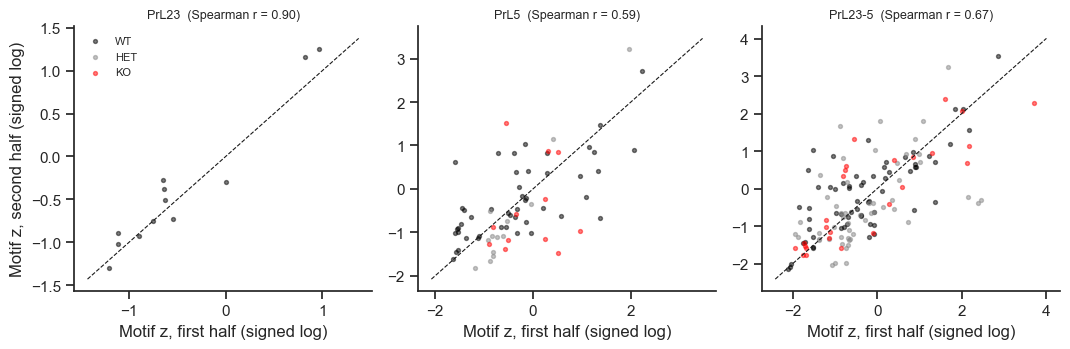

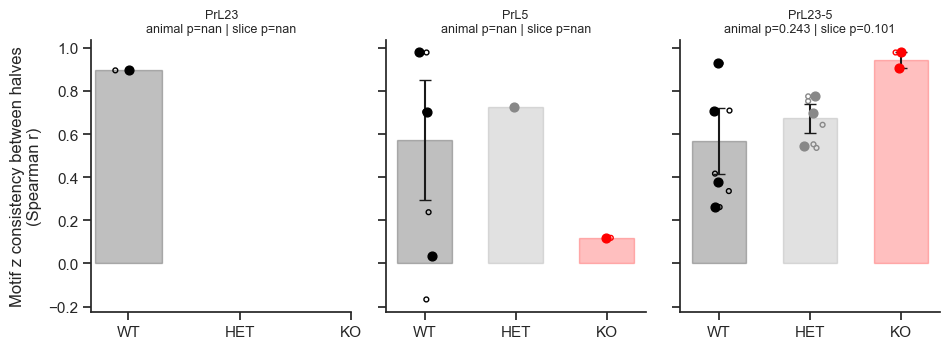

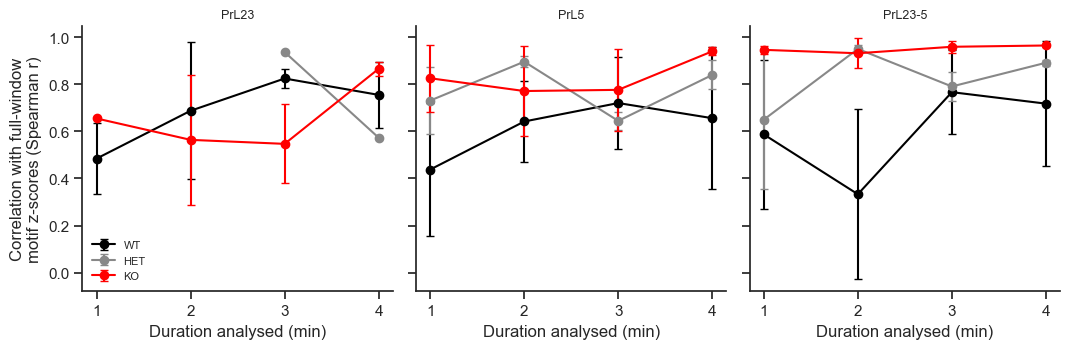

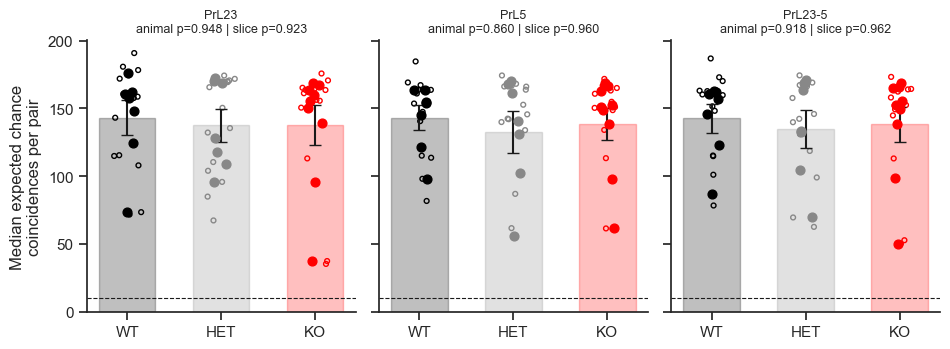

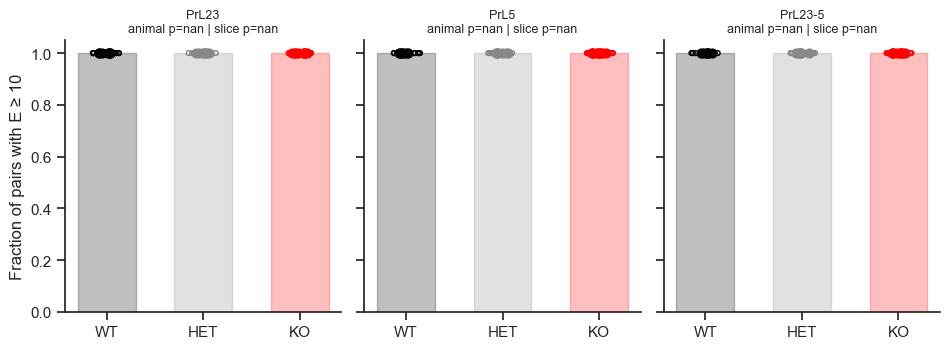


=== Consistency between halves (Spearman r, mean ± SEM across animals) ===
                  mean   sem  count
layer   genotype                   
PrL23   HET        NaN   NaN      0
        KO         NaN   NaN      0
        WT        0.90   NaN      1
PrL23-5 HET       0.67  0.07      3
        KO        0.94  0.04      2
        WT        0.57  0.15      4
PrL5    HET       0.73   NaN      1
        KO        0.12   NaN      1
        WT        0.57  0.28      3

=== Convergence (r with full window) ===
                      mean   sem
layer   duration_min            
PrL23   1             0.54  0.10
        2             0.63  0.17
        3             0.74  0.10
        4             0.76  0.08
PrL23-5 1             0.70  0.15
        2             0.74  0.15
        3             0.82  0.07
        4             0.84  0.10
PrL5    1             0.63  0.13
        2             0.75  0.09
        3             0.71  0.09
        4             0.79  0.12

=== Events per channel 

In [38]:
import re, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from scipy import stats

# ================= settings
ROOT = Path(r"D:\UMICH\PaperSubmission\Deep_Learning\Data\Spike Detection\Output")
OUT = ROOT / "Window_sufficiency"
OUT.mkdir(exist_ok=True)

GENOTYPES = ['WT', 'HET', 'KO']
GENOTYPE_COLORS = {'WT': '#000000', 'HET': '#888888', 'KO': '#FF0000'}
LAYERS = {'PrL23': 'PrL_L23', 'PrL5': 'PrL_L5', 'PrL23-5': 'PrL_'}   # name -> channel-key prefix
LAG = (0.0005, 0.005)        # s, directed lag window (same as the per-slice notebook)
Z_EDGE = 3.0                 # z threshold for a connection
N_SURR = 100                 # degree-preserving surrogate networks per estimate
DURATIONS_MIN = [1, 2, 3, 4] # increasing durations compared with the full window
MIN_EXPECTED = 10            # adequate pair: >= 10 expected chance coincidences
TRIADS = ['021D', '021U', '021C', '111D', '111U', '030T', '030C',
          '201', '120D', '120U', '120C', '210', '300']           # the 13 connected 3-node motifs
rng = np.random.default_rng(0)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

# ================= functions
def connectivity(trains, T):
    """Directed coincidence z-matrix (j fires LAG after i) and expected chance coincidences E."""
    n = len(trains)
    counts = np.array([len(t) for t in trains], float)
    C = np.zeros((n, n))
    for i, ti in enumerate(trains):
        for j, tj in enumerate(trains):
            if i != j and len(ti) and len(tj):
                C[i, j] = np.sum(np.searchsorted(tj, ti + LAG[1], 'right') - np.searchsorted(tj, ti + LAG[0], 'right'))
    E = np.outer(counts, counts) * (LAG[1] - LAG[0]) / T
    np.fill_diagonal(E, 0)
    with np.errstate(divide='ignore', invalid='ignore'):
        Z = np.where(E > 0, (C - E) / np.sqrt(E), 0)
    np.fill_diagonal(Z, 0)
    return Z, E

def triad_counts(G):
    tc = nx.triadic_census(G)
    return np.array([tc[t] for t in TRIADS], float)

def motif_z(Z):
    """Motif z-scores: observed triad counts vs degree-preserving rewired networks."""
    G = nx.DiGraph()
    G.add_nodes_from(range(len(Z)))
    G.add_edges_from(zip(*np.where(Z > Z_EDGE)))
    if G.number_of_edges() < 3:
        return np.full(len(TRIADS), np.nan)
    obs = triad_counts(G)
    surr = []
    for _ in range(N_SURR):
        H = G.copy()
        try:
            nx.directed_edge_swap(H, nswap=2 * H.number_of_edges(),
                                  max_tries=100 * H.number_of_edges(), seed=int(rng.integers(1e9)))
        except Exception:
            continue
        surr.append(triad_counts(H))
    if len(surr) < 10:
        return np.full(len(TRIADS), np.nan)
    surr = np.array(surr)
    sd = surr.std(axis=0)
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where(sd > 0, (obs - surr.mean(axis=0)) / sd, np.nan)

def slog(z):
    return np.sign(z) * np.log1p(np.abs(z))

def corr(a, b):
    """Spearman correlation of two motif z-score profiles (signed-log), ignoring NaN motifs."""
    ok = np.isfinite(a) & np.isfinite(b)
    if ok.sum() < 5 or np.ptp(a[ok]) == 0 or np.ptp(b[ok]) == 0:
        return np.nan
    return stats.spearmanr(slog(a[ok]), slog(b[ok])).correlation

# ================= 1. run every slice
rows_cons, rows_conv, rows_pair, rows_motif = [], [], [], []
for npz in sorted(ROOT.rglob('*_spike_times.npz')):
    if OUT in npz.parents:
        continue
    geno = next((p.upper() for p in npz.relative_to(ROOT).parts if p.upper() in GENOTYPES), None)
    date = re.search(r'\d{4}-\d{2}-\d{2}', npz.name + ' ' + str(npz.parent))
    if geno is None or date is None:
        print('skipped:', npz); continue
    slice_id = npz.name.replace('_spike_times.npz', '')
    T = json.loads(npz.with_name(slice_id + '_detection_parameters.json').read_text())['recording']['duration_s']
    st = np.load(npz)
    base = dict(genotype=geno, animal=date.group(), slice=slice_id)
    print(f'{geno} {slice_id} ({T:.0f} s)')

    for layer, prefix in LAYERS.items():
        keys = [k for k in st.files if k.startswith(prefix)]
        if len(keys) < 3:
            continue
        trains = [np.sort(st[k]) for k in keys]

        # --- full window: events per channel pair
        Z_full, E = connectivity(trains, T)
        e = E[~np.eye(len(E), dtype=bool)]
        rows_pair.append({**base, 'layer': layer,
                          'median_events_per_channel': np.median([len(t) for t in trains]),
                          'median_expected_coinc': np.median(e),
                          'frac_pairs_adequate': np.mean(e >= MIN_EXPECTED)})
        m_full = motif_z(Z_full)

        # --- non-overlapping halves
        h = T / 2
        Z1, _ = connectivity([t[t < h] for t in trains], h)
        Z2, _ = connectivity([t[t >= h] - h for t in trains], h)
        m1, m2 = motif_z(Z1), motif_z(Z2)
        rows_cons.append({**base, 'layer': layer, 'r_halves': corr(m1, m2)})
        for name, a, b in zip(TRIADS, m1, m2):
            rows_motif.append({**base, 'layer': layer, 'motif': name, 'z_first_half': a, 'z_second_half': b})

        # --- increasing duration vs full window
        for d in DURATIONS_MIN:
            Td = min(d * 60, T)
            Zd, _ = connectivity([t[t < Td] for t in trains], Td)
            rows_conv.append({**base, 'layer': layer, 'duration_min': d, 'r_vs_full': corr(motif_z(Zd), m_full)})

cons, conv = pd.DataFrame(rows_cons), pd.DataFrame(rows_conv)
pair, motif = pd.DataFrame(rows_pair), pd.DataFrame(rows_motif)
for df, name in [(cons, 'consistency_halves'), (conv, 'convergence_duration'),
                 (pair, 'events_per_pair'), (motif, 'motif_z_halves')]:
    df.to_csv(OUT / f'{name}_slice.csv', index=False)

# animal level = mean of slices
cons_a = cons.groupby(['genotype', 'animal', 'layer'], as_index=False).mean(numeric_only=True)
conv_a = conv.groupby(['genotype', 'animal', 'layer', 'duration_min'], as_index=False).mean(numeric_only=True)
pair_a = pair.groupby(['genotype', 'animal', 'layer'], as_index=False).mean(numeric_only=True)
cons_a.to_csv(OUT / 'consistency_halves_animal.csv', index=False)
conv_a.to_csv(OUT / 'convergence_duration_animal.csv', index=False)
pair_a.to_csv(OUT / 'events_per_pair_animal.csv', index=False)

# ================= 2. figures
def anova_p(df, col):
    g = [df.loc[df.genotype == x, col].dropna() for x in GENOTYPES]
    return stats.f_oneway(*g).pvalue if all(len(x) >= 2 for x in g) else np.nan

def bars(df_a, df_s, col, ylabel, fname, hline=None):
    """Bar = mean ± SEM of animals, filled dots = animals, open dots = slices; one panel per layer."""
    fig, axes = plt.subplots(1, len(LAYERS), figsize=(3.2 * len(LAYERS), 3.6), sharey=True)
    for ax, layer in zip(axes, LAYERS):
        a_l, s_l = df_a[df_a.layer == layer], df_s[df_s.layer == layer]
        for i, g in enumerate(GENOTYPES):
            c = GENOTYPE_COLORS[g]
            a = a_l.loc[a_l.genotype == g, col].dropna()
            s = s_l.loc[s_l.genotype == g, col].dropna()
            ax.bar(i, a.mean(), yerr=a.sem(), width=0.6, color=c, alpha=0.25, edgecolor=c, capsize=4)
            ax.scatter(i + rng.uniform(-0.15, 0.15, len(s)), s, s=12, facecolors='none', edgecolors=c)
            ax.scatter(i + rng.uniform(-0.08, 0.08, len(a)), a, s=40, color=c, zorder=3)
        if hline is not None:
            ax.axhline(hline, color='k', ls='--', lw=0.8)
        p_a, p_s = anova_p(a_l, col), anova_p(s_l, col)
        ax.set_title(f'{layer}\nanimal p={p_a:.3f} | slice p={p_s:.3f}', fontsize=9)
        ax.set_xticks(range(len(GENOTYPES))); ax.set_xticklabels(GENOTYPES)
    axes[0].set_ylabel(ylabel)
    fig.tight_layout()
    fig.savefig(OUT / f'{fname}.png', dpi=300); fig.savefig(OUT / f'{fname}.pdf'); plt.show()

# 2a. first vs second half, every motif of every slice
fig, axes = plt.subplots(1, len(LAYERS), figsize=(3.6 * len(LAYERS), 3.6))
for ax, layer in zip(axes, LAYERS):
    d = motif[(motif.layer == layer)].dropna(subset=['z_first_half', 'z_second_half'])
    for g in GENOTYPES:
        dg = d[d.genotype == g]
        ax.scatter(slog(dg.z_first_half), slog(dg.z_second_half), s=8, color=GENOTYPE_COLORS[g], alpha=0.5, label=g)
    lim = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lim, lim, 'k--', lw=0.8)
    r = stats.spearmanr(d.z_first_half, d.z_second_half).correlation if len(d) > 2 else np.nan
    ax.set_title(f'{layer}  (Spearman r = {r:.2f})', fontsize=9)
    ax.set_xlabel('Motif z, first half (signed log)')
axes[0].set_ylabel('Motif z, second half (signed log)')
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT / 'motif_z_first_vs_second_half.png', dpi=300); fig.savefig(OUT / 'motif_z_first_vs_second_half.pdf'); plt.show()

# 2b. consistency between halves per slice/animal
bars(cons_a, cons, 'r_halves', 'Motif z consistency between halves\n(Spearman r)', 'consistency_halves')

# 2c. convergence with increasing duration
fig, axes = plt.subplots(1, len(LAYERS), figsize=(3.6 * len(LAYERS), 3.6), sharey=True)
for ax, layer in zip(axes, LAYERS):
    for g in GENOTYPES:
        d = conv_a[(conv_a.layer == layer) & (conv_a.genotype == g)]
        m = d.groupby('duration_min').r_vs_full.agg(['mean', 'sem'])
        ax.errorbar(m.index, m['mean'], yerr=m['sem'], color=GENOTYPE_COLORS[g], marker='o', capsize=3, label=g)
    ax.set_title(layer, fontsize=9)
    ax.set_xlabel('Duration analysed (min)')
    ax.set_xticks(DURATIONS_MIN)
axes[0].set_ylabel('Correlation with full-window\nmotif z-scores (Spearman r)')
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT / 'convergence_duration.png', dpi=300); fig.savefig(OUT / 'convergence_duration.pdf'); plt.show()

# 2d. events per channel pair
bars(pair_a, pair, 'median_expected_coinc', 'Median expected chance\ncoincidences per pair', 'expected_coincidences', hline=MIN_EXPECTED)
bars(pair_a, pair, 'frac_pairs_adequate', f'Fraction of pairs with E ≥ {MIN_EXPECTED}', 'frac_pairs_adequate')

# ================= 3. numbers for the text (animal level)
print('\n=== Consistency between halves (Spearman r, mean ± SEM across animals) ===')
print(cons_a.groupby(['layer', 'genotype']).r_halves.agg(['mean', 'sem', 'count']).round(2))
print('\n=== Convergence (r with full window) ===')
print(conv_a.groupby(['layer', 'duration_min']).r_vs_full.agg(['mean', 'sem']).round(2))
print('\n=== Events per channel pair ===')
print(pair_a.groupby(['layer', 'genotype'])[['median_events_per_channel', 'median_expected_coinc',
                                              'frac_pairs_adequate']].mean().round(2))

# Coherence & Granger Causality

In [59]:
# import re
# import numpy as np
# import pandas as pd
# import seaborn as sns
# import matplotlib.pyplot as plt
# from scipy import stats
# from statsmodels.stats.multicomp import pairwise_tukeyhsd
# from statannotations.Annotator import Annotator

# # -------------------------
# # SETTINGS
# # -------------------------
# file_path = r"D:\UMICH\PaperSubmission\Deep_Learning\Data\Coherence_Granger_Motif_Results\combined_Coherence_GC.xlsx"
# OUT = r"D:\UMICH\PaperSubmission\Deep_Learning\Data\Coherence_Granger_Motif_Results\Coherence_Granger_Motif_Results"

# OUTLIER_IQR = 1.5     # slice-level outlier removal BEFORE averaging per animal; None = no removal
# order   = ["WT", "HET", "KO"]
# palette = {"WT": "#000000", "HET": "#888888", "KO": "#FF0000"}
# pairs   = [("WT", "HET"), ("WT", "KO"), ("HET", "KO")]
# size, alpha = 20, 1.0

# # -------------------------
# # LOAD + CLEAN
# # -------------------------
# df = pd.read_excel(file_path)
# df["Layer_clean"] = df["Layer"].replace({"L23": "L2/3", "L5": "L5", "L23_5": "L23→L5", "L5_23": "L5→L23"})

# # animal = recording date in the file name (all slices from one date = one mouse)
# df["Animal"] = df["MouseID"].astype(str).str.extract(r"(\d{1,2}-\d{2}-\d{2})")[0]
# missing = df[df["Animal"].isna()]["MouseID"].unique()
# if len(missing):
#     print("WARNING - no date found, file used as its own animal:", missing)
#     df["Animal"] = df["Animal"].fillna(df["MouseID"].astype(str))

# def remove_outliers_iqr(data, value_col, k):
#     """Remove outlier SLICES within each Band x Layer x Strain group (animals are kept)."""
#     if k is None:
#         return data
#     def keep(g):
#         q1, q3 = g[value_col].quantile([0.25, 0.75])
#         return g[(g[value_col] >= q1 - k * (q3 - q1)) & (g[value_col] <= q3 + k * (q3 - q1))]
#     return data.groupby(["Band", "Layer_clean", "Strain"], group_keys=False).apply(keep)

# def to_animal_level(value_col):
#     d = df[df[value_col].notna()].copy()
#     n_before = len(d)
#     d = remove_outliers_iqr(d, value_col, OUTLIER_IQR)
#     print(f"{value_col}: {n_before - len(d)} of {n_before} slice values removed as outliers")
#     a = (d.groupby(["Strain", "Animal", "Band", "Layer_clean"], as_index=False)[value_col].mean())
#     print(a.groupby("Strain")["Animal"].nunique().reindex(order).rename("n_animals"))
#     return a

# df_coh = to_animal_level("Coherence")
# df_gc  = to_animal_level("Granger Causality")

# # -------------------------
# # STATS: one-way ANOVA + Tukey per Band x Layer (one value per animal per test)
# # -------------------------
# conditions = [(b, l) for b in ["GBO", "HFO"] for l in ["L2/3", "L5", "L23→L5", "L5→L23"]]

# def run_stats(data, value_col):
#     rows = []
#     for band, layer in conditions:
#         sub = data[(data.Band == band) & (data.Layer_clean == layer)]
#         groups = [sub.loc[sub.Strain == g, value_col].values for g in order]
#         if sub.empty or any(len(x) < 2 for x in groups):
#             continue
#         F, p = stats.f_oneway(*groups)
#         tk = pairwise_tukeyhsd(sub[value_col], sub["Strain"])
#         tk_p = dict(zip([f"{a}_vs_{b}" for a, b in zip(tk.groupsunique[tk._multicomp.pairindices[0]],
#                                                            tk.groupsunique[tk._multicomp.pairindices[1]])],
#                         tk.pvalues))
#         rows.append({"Band": band, "Layer": layer,
#                      **{f"n_{g}": len(x) for g, x in zip(order, groups)},
#                      **{f"mean_{g}": x.mean() for g, x in zip(order, groups)},
#                      "F": F, "p_anova": p, **{f"tukey_p_{k}": v for k, v in tk_p.items()}})
#     res = pd.DataFrame(rows)
#     res.to_csv(f"{OUT}\\stats_animal_level_{value_col.replace(' ', '_')}.csv", index=False)
#     print(f"\n=== {value_col}: one-way ANOVA per band x layer (animal level) ===")
#     print(res[["Band", "Layer", "n_WT", "n_HET", "n_KO", "F", "p_anova"]].round(4).to_string(index=False))
#     return res

# stats_coh = run_stats(df_coh, "Coherence")
# stats_gc  = run_stats(df_gc, "Granger Causality")

# # -------------------------
# # PLOT: bar = mean ± SEM of animals, dots = animals, Welch + BH stars
# # -------------------------
# def make_plot(data, value_col, res, title, save_name):
#     fig, axes = plt.subplots(2, 4, figsize=(20, 10), sharey=True)
#     for ax, (band, layer) in zip(axes.flatten(), conditions):
#         sub = data[(data.Band == band) & (data.Layer_clean == layer)]
#         if sub.empty:
#             ax.set_visible(False)
#             continue
#         sns.barplot(data=sub, x="Strain", y=value_col, order=order, palette=palette,
#                     errorbar="se", edgecolor="k", alpha=0.5, ax=ax)
#         sns.stripplot(data=sub, x="Strain", y=value_col, order=order, palette=palette,
#                       size=size, alpha=alpha, linewidth=1, edgecolor="w", ax=ax)

#         label = "L2/3–L5" if (value_col == "Coherence" and layer == "L23→L5") else layer   # coherence has no direction
#         r = res[(res.Band == band) & (res.Layer == layer)]
#         p_txt = f"ANOVA p={r.p_anova.iloc[0]:.3f}" if len(r) else ""
#         ax.set_title(f"{band} - {label}\n{p_txt}", fontsize=12)
#         ax.set_xlabel(""); ax.set_ylabel(value_col)
#         ax.spines[["top", "right"]].set_visible(False)

#         valid = [p for p in pairs if p[0] in sub.Strain.values and p[1] in sub.Strain.values]
#         if valid:
#             try:
#                 ann = Annotator(ax, valid, data=sub, x="Strain", y=value_col, order=order)
#                 ann.configure(test="t-test_welch", comparisons_correction="BH", text_format="star",
#                               loc="outside", show_test_name=False, verbose=0)
#                 ann.apply_and_annotate()
#             except Exception as e:
#                 print(f"Annotation failed {band}-{layer}: {e}")

#     plt.suptitle(f"{title} (animal level)", fontsize=16, y=1.02)
#     plt.tight_layout()
#     plt.savefig(f"{OUT}\\{save_name}_animal.png", dpi=300, bbox_inches="tight")
#     plt.savefig(f"{OUT}\\{save_name}_animal.svg", bbox_inches="tight")
#     plt.show()

# make_plot(df_coh, "Coherence", stats_coh, "Coherence by Band, Layer and Genotype", "coherence_plot")
# make_plot(df_gc, "Granger Causality", stats_gc, "Granger Causality by Band, Layer and Genotype", "granger_plot")

In [58]:
# pd.set_option("display.width", 250)
# print("=== Coherence ===")
# print(stats_coh.round(4).to_string(index=False))
# print("\n=== Granger Causality ===")
# print(stats_gc.round(4).to_string(index=False))

Coherence: 30 of 276 slice values removed as outliers
Strain
WT     7
HET    7
KO     9
Name: n_animals, dtype: int64
Granger Causality: 23 of 368 slice values removed as outliers
Strain
WT     7
HET    7
KO     9
Name: n_animals, dtype: int64

=== Coherence - GBO: one-way ANOVA per layer (animal level) ===
 Layer  n_WT  n_HET  n_KO      F  p_anova
  L2/3     7      7     9 0.0005   0.9995
    L5     7      7     8 1.0525   0.3685
L23→L5     7      7     9 0.7987   0.4638


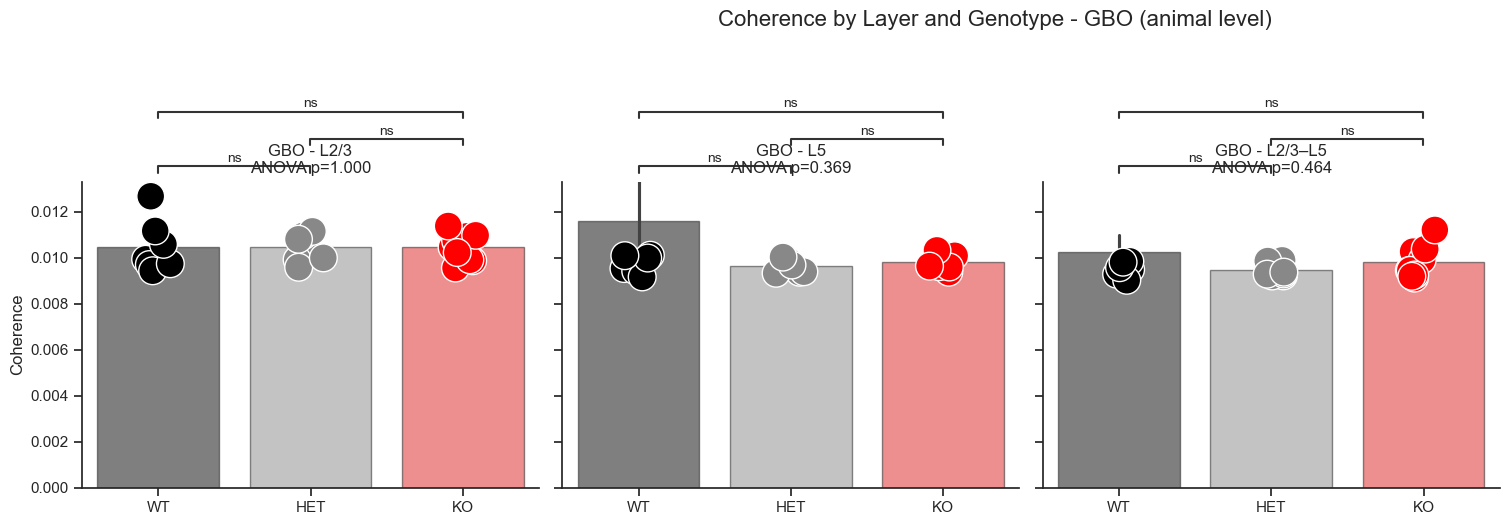


=== Granger Causality - GBO: one-way ANOVA per layer (animal level) ===
 Layer  n_WT  n_HET  n_KO      F  p_anova
  L2/3     7      7     8 3.4506   0.0527
    L5     7      6     8 4.7465   0.0221
L23→L5     7      7     8 3.6704   0.0449
L5→L23     7      7     8 3.8173   0.0404


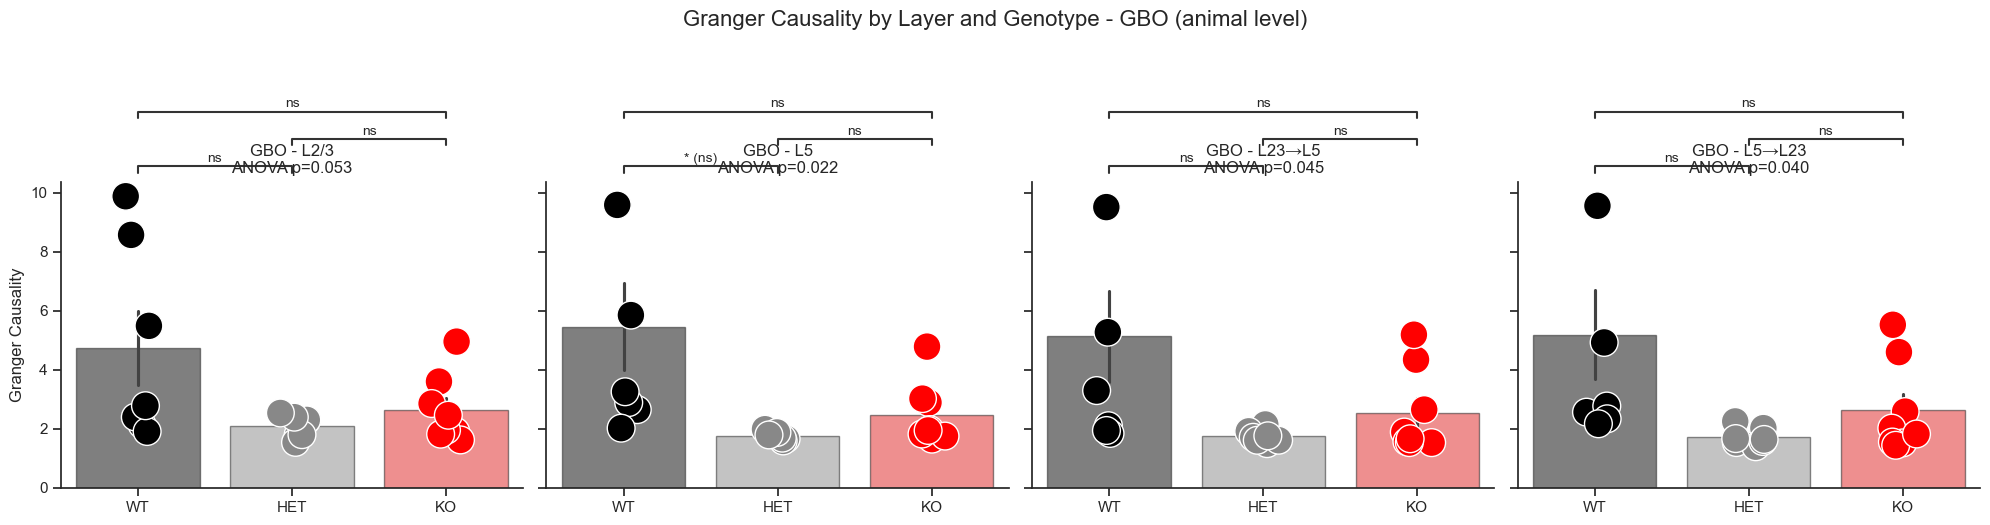


=== Coherence - HFO: one-way ANOVA per layer (animal level) ===
 Layer  n_WT  n_HET  n_KO      F  p_anova
  L2/3     7      7     9 1.7975   0.1915
    L5     7      7     8 4.3782   0.0273
L23→L5     7      7     8 2.2835   0.1292


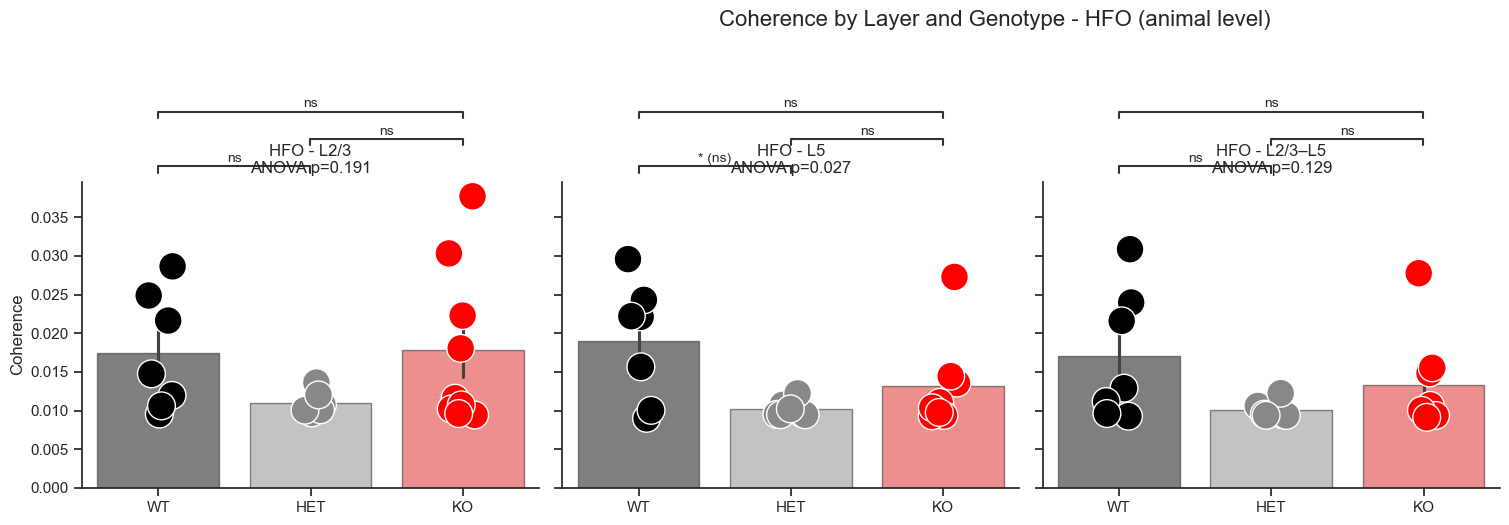


=== Granger Causality - HFO: one-way ANOVA per layer (animal level) ===
 Layer  n_WT  n_HET  n_KO      F  p_anova
  L2/3     7      7     9 1.9251   0.1719
    L5     7      7     7 8.2793   0.0028
L23→L5     7      7     9 1.7392   0.2012
L5→L23     7      7     9 1.6354   0.2199


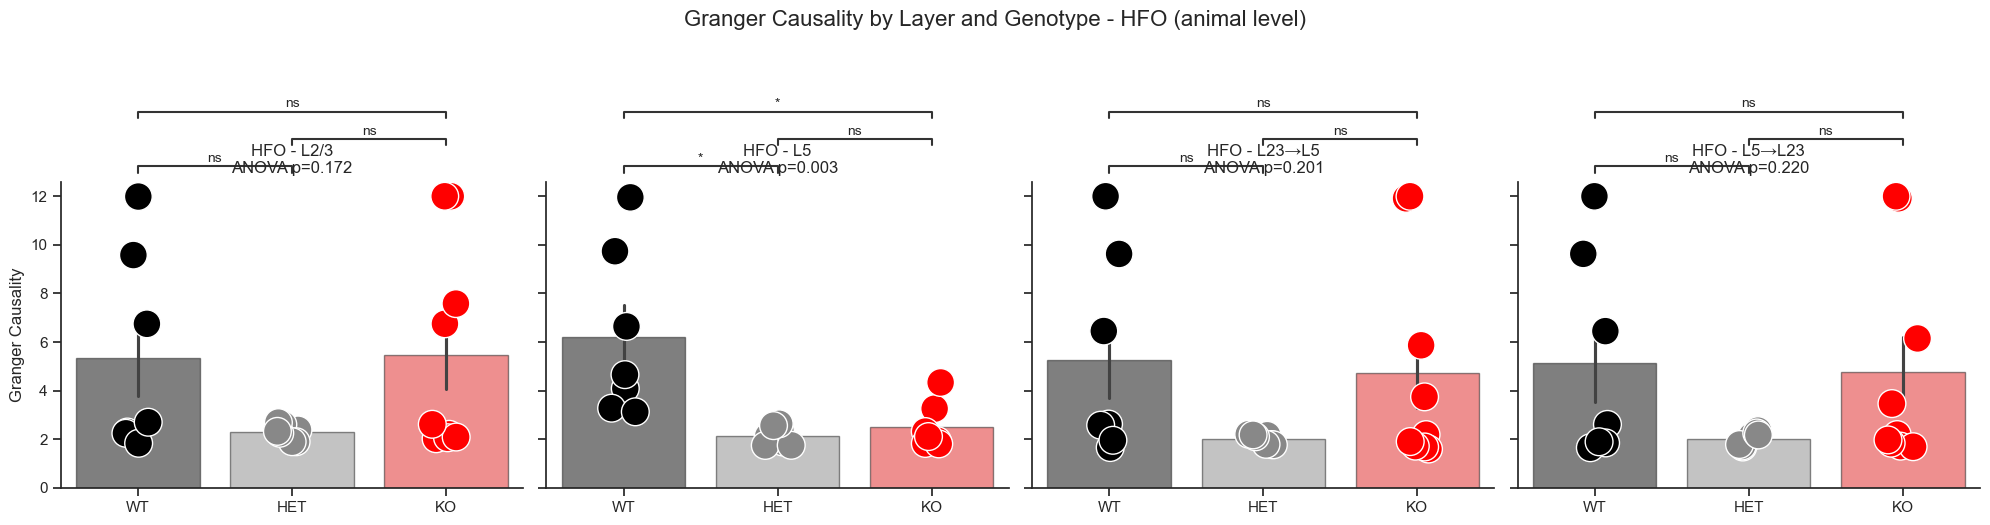

In [57]:
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statannotations.Annotator import Annotator

# -------------------------
# SETTINGS
# -------------------------
file_path = r"D:\UMICH\PaperSubmission\Deep_Learning\Data\Coherence_Granger_Motif_Results\combined_Coherence_GC.xlsx"
OUT = r"D:\UMICH\PaperSubmission\Deep_Learning\Data\Coherence_Granger_Motif_Results\Coherence_Granger_Motif_Results"

OUTLIER_IQR = 1.5     # slice-level outlier removal BEFORE averaging per animal; None = no removal
order   = ["WT", "HET", "KO"]
palette = {"WT": "#000000", "HET": "#888888", "KO": "#FF0000"}
pairs   = [("WT", "HET"), ("WT", "KO"), ("HET", "KO")]
size, alpha = 20, 1.0

BANDS  = ["GBO", "HFO"]                          # analysed separately
LAYERS = ["L2/3", "L5", "L23→L5", "L5→L23"]

# -------------------------
# LOAD + CLEAN
# -------------------------
df = pd.read_excel(file_path)
df["Layer_clean"] = df["Layer"].replace({"L23": "L2/3", "L5": "L5", "L23_5": "L23→L5", "L5_23": "L5→L23"})

# animal = recording date in the file name (all slices from one date = one mouse)
df["Animal"] = df["MouseID"].astype(str).str.extract(r"(\d{1,2}-\d{2}-\d{2})")[0]
missing = df[df["Animal"].isna()]["MouseID"].unique()
if len(missing):
    print("WARNING - no date found, file used as its own animal:", missing)
    df["Animal"] = df["Animal"].fillna(df["MouseID"].astype(str))

def remove_outliers_iqr(data, value_col, k):
    """Remove outlier SLICES within each Band x Layer x Strain group (animals are kept)."""
    if k is None:
        return data
    def keep(g):
        q1, q3 = g[value_col].quantile([0.25, 0.75])
        return g[(g[value_col] >= q1 - k * (q3 - q1)) & (g[value_col] <= q3 + k * (q3 - q1))]
    return data.groupby(["Band", "Layer_clean", "Strain"], group_keys=False).apply(keep)

def to_animal_level(value_col):
    d = df[df[value_col].notna()].copy()
    n_before = len(d)
    d = remove_outliers_iqr(d, value_col, OUTLIER_IQR)
    print(f"{value_col}: {n_before - len(d)} of {n_before} slice values removed as outliers")
    a = (d.groupby(["Strain", "Animal", "Band", "Layer_clean"], as_index=False)[value_col].mean())
    print(a.groupby("Strain")["Animal"].nunique().reindex(order).rename("n_animals"))
    return a

df_coh = to_animal_level("Coherence")
df_gc  = to_animal_level("Granger Causality")

# -------------------------
# STATS: one-way ANOVA + Tukey per layer, separately for each band
# -------------------------
def run_stats(data, value_col, band):
    rows = []
    for layer in LAYERS:
        sub = data[(data.Band == band) & (data.Layer_clean == layer)]
        groups = [sub.loc[sub.Strain == g, value_col].values for g in order]
        if sub.empty or any(len(x) < 2 for x in groups):
            continue
        F, p = stats.f_oneway(*groups)
        tk = pairwise_tukeyhsd(sub[value_col], sub["Strain"])
        tk_p = dict(zip([f"{a}_vs_{b}" for a, b in zip(tk.groupsunique[tk._multicomp.pairindices[0]],
                                                           tk.groupsunique[tk._multicomp.pairindices[1]])],
                        tk.pvalues))
        rows.append({"Band": band, "Layer": layer,
                     **{f"n_{g}": len(x) for g, x in zip(order, groups)},
                     **{f"mean_{g}": x.mean() for g, x in zip(order, groups)},
                     "F": F, "p_anova": p, **{f"tukey_p_{k}": v for k, v in tk_p.items()}})
    res = pd.DataFrame(rows)
    from statsmodels.stats.multitest import multipletests
    res["q_bh"] = multipletests(res["p_anova"], method="fdr_bh")[1]
    res.to_csv(f"{OUT}\\stats_animal_level_{value_col.replace(' ', '_')}_{band}.csv", index=False)
    print(f"\n=== {value_col} - {band}: one-way ANOVA per layer (animal level) ===")
    print(res[["Layer", "n_WT", "n_HET", "n_KO", "F", "p_anova"]].round(4).to_string(index=False))
    return res

# -------------------------
# PLOT: one figure per band; bar = mean ± SEM of animals, dots = animals, Welch + BH stars
# -------------------------
def make_plot(data, value_col, res, band, title, save_name):
    fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)
    for ax, layer in zip(axes, LAYERS):
        sub = data[(data.Band == band) & (data.Layer_clean == layer)]
        if sub.empty:
            ax.set_visible(False)
            continue
        sns.barplot(data=sub, x="Strain", y=value_col, order=order, palette=palette,
                    errorbar="se", edgecolor="k", alpha=0.5, ax=ax)
        sns.stripplot(data=sub, x="Strain", y=value_col, order=order, palette=palette,
                      size=size, alpha=alpha, linewidth=1, edgecolor="w", ax=ax)

        label = "L2/3–L5" if (value_col == "Coherence" and layer == "L23→L5") else layer   # coherence has no direction
        r = res[res.Layer == layer]
        p_txt = f"ANOVA p={r.p_anova.iloc[0]:.3f}" if len(r) else ""
        ax.set_title(f"{band} - {label}\n{p_txt}", fontsize=12)
        ax.set_xlabel(""); ax.set_ylabel(value_col)
        ax.spines[["top", "right"]].set_visible(False)

        valid = [p for p in pairs if p[0] in sub.Strain.values and p[1] in sub.Strain.values]
        if valid:
            try:
                ann = Annotator(ax, valid, data=sub, x="Strain", y=value_col, order=order)
                ann.configure(test="t-test_welch", comparisons_correction="BH", text_format="star",
                              loc="outside", show_test_name=False, verbose=0)
                ann.apply_and_annotate()
            except Exception as e:
                print(f"Annotation failed {band}-{layer}: {e}")

    plt.suptitle(f"{title} - {band} (animal level)", fontsize=16, y=1.04)
    plt.tight_layout()
    plt.savefig(f"{OUT}\\{save_name}_{band}_animal.png", dpi=300, bbox_inches="tight")
    plt.savefig(f"{OUT}\\{save_name}_{band}_animal.svg", bbox_inches="tight")
    plt.show()

# -------------------------
# RUN: each band separately
# -------------------------
stats_coh, stats_gc = {}, {}
for band in BANDS:
    stats_coh[band] = run_stats(df_coh, "Coherence", band)
    make_plot(df_coh, "Coherence", stats_coh[band], band, "Coherence by Layer and Genotype", "coherence_plot")

    stats_gc[band] = run_stats(df_gc, "Granger Causality", band)
    make_plot(df_gc, "Granger Causality", stats_gc[band], band, "Granger Causality by Layer and Genotype", "granger_plot")

In [56]:
pd.set_option("display.width", 250)
for band in BANDS:
    print(f"=== Coherence - {band} ===")
    print(stats_coh[band].round(4).to_string(index=False))
    print(f"\n=== Granger Causality - {band} ===")
    print(stats_gc[band].round(4).to_string(index=False))
    print()

=== Coherence - GBO ===
Band  Layer  n_WT  n_HET  n_KO  mean_WT  mean_HET  mean_KO      F  p_anova  tukey_p_HET_vs_KO  tukey_p_HET_vs_WT  tukey_p_KO_vs_WT
 GBO   L2/3     7      7     9   0.0105    0.0105   0.0105 0.0005   0.9995             1.0000             0.9997            0.9995
 GBO     L5     7      7     8   0.0116    0.0096   0.0098 1.0525   0.3685             0.9914             0.4110            0.4562
 GBO L23→L5     7      7     9   0.0103    0.0095   0.0098 0.7987   0.4638             0.8261             0.4329            0.7398

=== Granger Causality - GBO ===
Band  Layer  n_WT  n_HET  n_KO  mean_WT  mean_HET  mean_KO      F  p_anova  tukey_p_HET_vs_KO  tukey_p_HET_vs_WT  tukey_p_KO_vs_WT
 GBO   L2/3     7      7     8   4.7380    2.0931   2.6474 3.4506   0.0527             0.8544             0.0565            0.1336
 GBO     L5     7      6     8   5.4651    1.7640   2.4800 4.7465   0.0221             0.8403             0.0283            0.0603
 GBO L23→L5     7      7  